# CSE 438 - Assignment 01
## Group Information
| Field | Details |
|----------------------------|----------------------------------------------|
| **Group ID** | Group B |
| **Student 1 Name** | Nasrullah Kaisher Sijan |
| **Student 1 ID** | 2023-1-60-204 |
| **Student 2 Name** | G M MOTA-TAHRIN TAYEF |
| **Student 2 ID** | 2022-1-60-109 |
| **Student 3 Name** | Bushra Tahsin |
| **Student 3 ID** | 2023-3-60-129 |
| **Notebook Type** | YOLOv26 (Semantic) Notebook |
| **Assignment 01 Best Acc** | Semantic Segmentation Model Benchmark-ing |
| **Dataset Name (Kaggle)** | /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset |
| **Dataset Source** | Pixel-wise Annotation for Clear and Contaminated Regions Segmentation in Wireless Capsule Endoscopy Images: Kvasir capsule endoscopy |
| **Dataset Source Link** | https://data.mendeley.com/datasets/vmxhn95j8z/3 |
| **Submission Date** | 14 July 2026 |

# YOLOv26 Semantic Segmentation for Kvasir Capsule Endoscopy Contamination Segmentation

## Task E (Model Training) · Task F (Testing & Quantitative Evaluation) · Task G (Error Analysis)

This notebook implements **Ultralytics YOLOv26 Semantic Segmentation only**
(model family `yolo26*-sem`, released by Ultralytics in January 2026).
DeepLabV3-ResNet50 and SegFormer-B0 are implemented in their own separate,
equally self-contained notebooks so that every model can be run,
inspected, and re-run independently.

## Purpose of semantic segmentation

Unlike image classification, which assigns one label to an entire image,
semantic segmentation assigns a class label to **every pixel**. For capsule
endoscopy quality control, this distinction matters directly: knowing that
a frame is "somewhat contaminated" is far less useful than knowing *which
regions* of the frame are obscured by bubbles or turbid fluid, since that
spatial information is what would let a downstream diagnostic system decide
whether a specific region of tissue was actually visible for inspection.

## Why YOLOv26 Semantic Segmentation is included in this benchmark

YOLOv26 (also written YOLO26) is Ultralytics' newest unified real-time
vision model family. Unlike its predecessors, whose segmentation support
was limited to instance segmentation (`yolo26*-seg`, one mask per detected
object), YOLO26 ships a dedicated **semantic segmentation task head**
(`yolo26*-sem`) that predicts one dense, whole-image class map directly —
architecturally the same *kind* of output DeepLabV3 and SegFormer-B0
produce, which is what makes a head-to-head comparison meaningful in the
first place. Where DeepLabV3 represents a mature, convolutional
encoder/ASPP-head baseline, YOLOv26 represents the opposite end of the
design-philosophy spectrum this project wants to benchmark: a backbone
whose entire lineage (YOLOv5 through YOLO26) was optimized for real-time
inference throughput and edge deployment, now repurposed for dense
per-pixel prediction rather than its original box-detection task.

## Advantages of YOLOv26's unified, real-time-first architecture

YOLO26 removes Distribution Focal Loss (DFL) and the Non-Maximum
Suppression (NMS) post-processing step that earlier YOLO generations
depended on, replacing them with a lighter, natively end-to-end head. While
those two specific changes are aimed at YOLO26's *detection* task, they
are symptomatic of the same design philosophy that carries over to its
semantic segmentation head: a smaller, simpler, more export-friendly
network with substantially lower latency than convolutional segmentation
baselines at comparable accuracy. For this project, where DeepLabV3,
SegFormer-B0, and YOLOv26 are compared on the *same* accuracy metrics
(Section 9), YOLOv26's throughput is the axis on which it is most likely to
distinguish itself, and Section 10's Computational Performance comparison
is designed to quantify that directly.

## Advantages of transfer learning (Cityscapes-pretrained backbone)

Training a segmentation backbone from random initialization requires far
more labeled data than this project's ~15k images to reach strong
performance. Ultralytics ships `yolo26n-sem.pt` / `yolo26s-sem.pt` /
etc. pretrained on **Cityscapes**, an urban street-scene semantic
segmentation dataset. Cityscapes is visually further from capsule
endoscopy imagery than COCO's natural-image categories are from it — but,
as with DeepLabV3's COCO pretraining, it is specifically the *low-level*
convolutional features (edges, textures, region boundaries, multi-scale
context) that transfer across visual domains, not the specific Cityscapes
class semantics. Initializing from Cityscapes weights therefore still
gives this notebook's fine-tuning run a substantially better starting
point than training YOLOv26's segmentation head from scratch on a dataset
this size.

## Why only the segmentation head's class count is adapted

YOLOv26's Cityscapes-pretrained checkpoint predicts 19 Cityscapes classes;
this project needs exactly 2 (Clear / Contaminated). Ultralytics' training
API handles this automatically: passing a dataset YAML whose `names`
mapping declares 2 classes causes the semantic segmentation head to be
rebuilt for 2 output channels before fine-tuning begins, while the
pretrained backbone's convolutional weights are preserved and loaded via
transfer learning — the same "keep the backbone, replace the head"
principle DeepLabV3's `model.classifier[-1]` replacement uses, just
performed by the `ultralytics` library rather than by hand.

## Expected advantages for medical image segmentation

Given this dataset's size (order 10-15k images) and its severe class
imbalance (17.12:1), a from-scratch-trained network would need
substantially more contaminated-region examples to learn reliable features
for the minority class unaided. Transfer learning shifts most of that
burden onto Cityscapes pretraining, and YOLOv26's semantic segmentation
head additionally combines Cross-Entropy with an internal Dice loss term
by architecture default (Section 5) — directly relevant given this
project's own EDA-driven preference for a CE + Dice hybrid loss.

## Why reproducibility is important

A reported mIoU or Dice score is only useful to a reader if it can be
independently checked. Every source of randomness in this notebook (data
split, augmentation, weight initialization of the replaced segmentation
head, data shuffling, Ultralytics' own internal seeding) is seeded
identically every run, and every hyperparameter lives in one explicit
configuration object (Section 5) rather than being scattered through the
notebook.

## Why all models must reuse the exact same preprocessing outputs

DeepLabV3, SegFormer-B0, and YOLOv26 are only comparable if they are
trained and evaluated on identical data, with identical augmentation and
identical class definitions. This notebook is **completely self-contained**
(it does not import code from any other notebook), but it reads its data
exclusively from Notebook 0's frozen preprocessing artifacts (`train.csv` /
`validation.csv` / `test.csv`, `augmentation_config.json`,
`label_mapping.json`) — the same artifacts every other model notebook
reads — so that any difference in final results reflects genuine model
differences, not inconsistent data handling. Section 3 additionally
materializes (never re-splits) these same rows into the on-disk image/mask
layout Ultralytics' training API requires; this is a required, architecture
-driven adaptation, not a new data split (see Section 3's Markdown for
details).

In [1]:
# ============================================================================
# IMPORTS
# ============================================================================
import json
import platform
import random
import shutil
import warnings
from datetime import datetime
from pathlib import Path
from typing import Any, Optional, Union

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from tqdm.auto import tqdm

import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Ultralytics provides the YOLOv26 model family (including the yolo26*-sem
# semantic segmentation task used throughout this notebook) via a single
# high-level `YOLO` class -- there is no torchvision equivalent, since
# YOLOv26 is not shipped through torchvision.
# Install Ultralytics
!pip install -q ultralytics
from ultralytics import YOLO
import ultralytics

# OpenCV is used for image/mask I/O, consistent with the coding style
# established in Notebook 0 -- not listed among the "preferred" libraries
# above, but genuinely required for reading the dataset's image/mask files.
import cv2
cv2.setNumThreads(0)  # avoid fighting with DataLoader's own worker processes

from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
})

print("Imports complete.")
print(f"  torch version         : {torch.__version__}")
print(f"  ultralytics version    : {ultralytics.__version__}")
print(f"  albumentations version : {A.__version__}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Imports complete.
  torch version         : 2.10.0+cu128
  ultralytics version    : 8.4.95
  albumentations version : 2.0.8


---
# Section 2 — Load Preprocessing Outputs

This notebook's **only** dependency is the set of artifacts Notebook 0
(`eda-and-data-prep.ipynb`) produced. Nothing here re-derives the data
split, re-designs augmentation, or recomputes any preprocessing decision —
doing so would risk this notebook silently drifting onto different data
than the DeepLabV3 and SegFormer-B0 notebooks use, which would invalidate
any comparison between them. Loading `train.csv` / `validation.csv` /
`test.csv` directly, byte-for-byte as Notebook 0 produced them, is what
**prevents data leakage** (no split is ever re-computed here) and
**guarantees reproducibility** (every model notebook sees exactly the same
samples, in the same split, with the same class encoding).

Per the professor's required structure, `PREPROCESSING_ROOT` below is the
single directory this entire notebook needs specified — every other path
is derived from it.

In [2]:
# ============================================================================
# CONFIGURATION -- the only path that should need editing
# ============================================================================

# Root of Notebook 0's exported preprocessing artifacts (the "dataset root
# directory" referred to by the professor's required structure -- this
# notebook consumes Notebook 0's *outputs*, never the raw image folders
# directly).
PREPROCESSING_ROOT = Path("/kaggle/input/datasets/nasrullahsijan/preprocessing-capsule/results")

TRAIN_CSV_PATH = PREPROCESSING_ROOT / "splits" / "train.csv"
VALIDATION_CSV_PATH = PREPROCESSING_ROOT / "splits" / "validation.csv"
TEST_CSV_PATH = PREPROCESSING_ROOT / "splits" / "test.csv"
AUGMENTATION_CONFIG_PATH = PREPROCESSING_ROOT / "augmentation" / "augmentation_config.json"
PREPROCESSING_METADATA_PATH = PREPROCESSING_ROOT / "metadata" / "preprocessing_metadata.json"
LABEL_MAPPING_PATH = PREPROCESSING_ROOT / "metadata" / "label_mapping.json"

# NOTE ON A NAMING DISCREPANCY: this notebook's task brief lists the master
# dataset manifest as `metadata/dataset_manifest.csv`. Notebook 0 actually
# exports this file as `dataset/dataset_master.csv`. Both candidate
# locations are checked below so this notebook works against Notebook 0's
# real output regardless of which naming convention is in effect.
_DATASET_MANIFEST_CANDIDATES = [
    PREPROCESSING_ROOT / "metadata" / "dataset_manifest.csv",
    PREPROCESSING_ROOT / "dataset" / "dataset_master.csv",
]

# This notebook's OWN outputs (figures, configuration, checkpoints, etc.)
# are kept entirely separate from Notebook 0's (read-only) artifacts above,
# in a model-specific sub-tree so DeepLabV3/SegFormer-B0/YOLOv26 outputs
# never collide.
OUTPUT_DIR = Path("results/yolov26")
FIGURES_DIR = OUTPUT_DIR / "figures"
CONFIG_DIR = OUTPUT_DIR / "config"
for directory in (OUTPUT_DIR, FIGURES_DIR, CONFIG_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"PREPROCESSING_ROOT : {PREPROCESSING_ROOT.resolve()}")
print(f"OUTPUT_DIR          : {OUTPUT_DIR.resolve()}")

PREPROCESSING_ROOT : /kaggle/input/datasets/nasrullahsijan/preprocessing-capsule/results
OUTPUT_DIR          : /kaggle/working/results/yolov26


In [3]:
# ============================================================================
# VALIDATE THAT EVERY REQUIRED PREPROCESSING ARTIFACT EXISTS
# ============================================================================

class PreprocessingArtifactsMissingError(RuntimeError):
    """Raised when a required Notebook 0 preprocessing artifact is missing.
    This notebook must stop execution rather than continue with partial or
    substitute data -- see Section 2's Markdown explanation.
    """


DATASET_MANIFEST_PATH = next((p for p in _DATASET_MANIFEST_CANDIDATES if p.is_file()), None)

required_files: dict[str, Optional[Path]] = {
    "train.csv": TRAIN_CSV_PATH,
    "validation.csv": VALIDATION_CSV_PATH,
    "test.csv": TEST_CSV_PATH,
    "augmentation_config.json": AUGMENTATION_CONFIG_PATH,
    "preprocessing_metadata.json": PREPROCESSING_METADATA_PATH,
    "label_mapping.json": LABEL_MAPPING_PATH,
    "dataset_manifest.csv (dataset_master.csv)": DATASET_MANIFEST_PATH,
}

validation_rows = [
    {"artifact": name, "expected_path": str(path) if path else "NOT FOUND", "found": bool(path and path.is_file())}
    for name, path in required_files.items()
]
validation_df = pd.DataFrame(validation_rows)
display(validation_df)

_missing = validation_df.loc[~validation_df["found"], "artifact"].tolist()
if _missing:
    raise PreprocessingArtifactsMissingError(
        f"The following required Notebook 0 artifacts are missing under "
        f"'{PREPROCESSING_ROOT.resolve()}': {_missing}. Run "
        f"`eda-and-data-prep.ipynb` to completion before running this "
        f"notebook, or correct PREPROCESSING_ROOT above."
    )
print(f"\nAll {len(required_files)} required preprocessing artifacts were found.")

,artifact,expected_path,found
0,train.csv,/kaggle/input/datasets/nasrullahsijan/preproce...,True
1,validation.csv,/kaggle/input/datasets/nasrullahsijan/preproce...,True
2,test.csv,/kaggle/input/datasets/nasrullahsijan/preproce...,True
3,augmentation_config.json,/kaggle/input/datasets/nasrullahsijan/preproce...,True
4,preprocessing_metadata.json,/kaggle/input/datasets/nasrullahsijan/preproce...,True
5,label_mapping.json,/kaggle/input/datasets/nasrullahsijan/preproce...,True
6,dataset_manifest.csv (dataset_master.csv),/kaggle/input/datasets/nasrullahsijan/preproce...,True



All 7 required preprocessing artifacts were found.


In [4]:
# ============================================================================
# LOAD METADATA AND DISPLAY A SUMMARY
# ============================================================================
with open(PREPROCESSING_METADATA_PATH) as f:
    preprocessing_metadata = json.load(f)
with open(LABEL_MAPPING_PATH) as f:
    label_mapping = json.load(f)
with open(AUGMENTATION_CONFIG_PATH) as f:
    augmentation_config = json.load(f)

train_df = pd.read_csv(TRAIN_CSV_PATH)
validation_df_split = pd.read_csv(VALIDATION_CSV_PATH)
test_df = pd.read_csv(TEST_CSV_PATH)

_dataset_info = preprocessing_metadata.get("dataset_information", {})
_split_info = preprocessing_metadata.get("split_information", {})
_class_info = preprocessing_metadata.get("class_information", {})
_randomness_info = preprocessing_metadata.get("randomness", {})

IMAGE_SIZE: tuple[int, int] = tuple(_dataset_info.get("image_size", (336, 336)))
NUM_CLASSES: int = len(_class_info.get("class_names_binary", [])) or 2
RANDOM_SEED: int = _randomness_info.get("random_seed", 42)

print("Preprocessing summary (loaded from Notebook 0, not recomputed):")
print(f"  Training samples     : {len(train_df)}")
print(f"  Validation samples    : {len(validation_df_split)}")
print(f"  Test samples           : {len(test_df)}")
print(f"  Image resolution         : {IMAGE_SIZE}")
print(f"  Number of classes          : {NUM_CLASSES}")
print(f"  Random seed                  : {RANDOM_SEED}")
print(f"  Pixel-level imbalance (EDA)    : {_class_info.get('pixel_imbalance_ratio')} "
      f"({_class_info.get('class_names_binary')})")
print(f"  Binary mask encoding (auto-detected) : {label_mapping}")

print("\nAugmentation pipeline summary:")
for step in augmentation_config.get("train_pipeline", []):
    print(f"  [{step['order']}] {step['name']:<24} p={step['probability']}")

Preprocessing summary (loaded from Notebook 0, not recomputed):
  Training samples     : 10526
  Validation samples    : 2206
  Test samples           : 2411
  Image resolution         : (336, 336)
  Number of classes          : 2
  Random seed                  : 42
  Pixel-level imbalance (EDA)    : 17.12:1 (['Contaminated', 'Clear'])
  Binary mask encoding (auto-detected) : {'0': 'Contaminated', '1': 'Clear', 'white_pixel_label': '1'}

Augmentation pipeline summary:
  [0] HorizontalFlip           p=0.5
  [1] Rotate                   p=0.5
  [2] RandomBrightnessContrast p=0.5
  [3] CLAHE                    p=0.3
  [4] RandomGamma              p=0.3
  [5] GaussNoise               p=0.2
  [6] GaussianBlur             p=0.15
  [7] Normalize                p=1.0
  [8] ToTensorV2               p=1.0


---
# Section 3 — Dataset & DataLoader

## Why verifying the DataLoader before model training matters

A `Dataset`/`DataLoader` bug (a misaligned mask, a wrong normalization
constant, a transform applied inconsistently between image and mask) does
not raise an exception -- the training loop will run to completion and
report numbers, just meaningless ones. The only reliable way to catch this
class of bug is to **look at actual batches** before spending any GPU time
training on them, which this section does explicitly (batch visualization,
below) rather than assuming the pipeline is correct because the code runs
without error.

The `Dataset` class, transform-loading logic, and class-index convention
below are implemented fresh in this notebook (per the "fully self-contained"
requirement) but are deliberately consistent with Notebook 0's design:
images are loaded as RGB via OpenCV, masks are read as grayscale and
remapped using Notebook 0's auto-detected `label_mapping.json` (never
assuming a fixed raw pixel encoding), and every augmentation parameter is
loaded from `augmentation_config.json` rather than redefined by hand.

**This `KvasirSegmentationDataset` / `DataLoader` pipeline is reused
verbatim from the DeepLabV3 and SegFormer-B0 notebooks.** Ultralytics'
training API does not accept a PyTorch `Dataset`/`DataLoader` directly (see
the Markdown after the batch-visualization cell below for why, and how the
same split is instead materialized on disk); this pipeline therefore is
*not* used to feed YOLOv26's own training loop, but it remains the single
source of ground truth for every batch visualization, qualitative
prediction grid, and error-analysis figure in Sections 3, 9, and 10 —
exactly as it is in the other two notebooks. This is what lets Sections 9
and 10 be shared, near-verbatim code across all three model notebooks.

In [5]:
# ============================================================================
# FIXED TRAINING CLASS CONVENTION
# ============================================================================
# Notebook 0 auto-detected which raw pixel value (white/black) corresponds
# to "Clear" vs "Contaminated" (label_mapping.json) but did not fix which
# integer class index every model notebook should train against. That
# convention is fixed once, here: Background/Clear = 0, Contaminated = 1.
FIXED_CLASS_MAPPING: dict[str, int] = {"Background": 0, "Clear": 0, "Contaminated": 1}
VALID_CLASS_INDICES = set(FIXED_CLASS_MAPPING.values())
CLASS_NAMES_BY_INDEX: list[str] = ["Clear", "Contaminated"]


class InvalidMaskError(ValueError):
    """Raised when a binary mask decodes to a pixel value outside {0, 1}."""


def load_image(path: Union[str, Path]) -> np.ndarray:
    """Load an image as an RGB uint8 array (OpenCV loads BGR by default)."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image at {path} (missing or corrupted).")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def load_binary_mask(path: Union[str, Path]) -> np.ndarray:
    """Load a Binary GT mask as a single-channel grayscale array (raw pixel
    values, not yet remapped to class indices).
    """
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(f"Could not read mask at {path} (missing or corrupted).")
    return mask


def mask_to_class_indices(raw_mask: np.ndarray, label_mapping: dict) -> np.ndarray:
    """Convert a raw grayscale mask into the fixed training convention
    (Clear=0, Contaminated=1), resolving the raw-pixel-value -> class-name
    mapping from Notebook 0's auto-detected `label_mapping.json`.
    """
    white_key = label_mapping["white_pixel_label"]
    black_key = "0" if white_key == "1" else "1"
    is_white = raw_mask >= 128
    class_indices = np.where(
        is_white, FIXED_CLASS_MAPPING[label_mapping[white_key]], FIXED_CLASS_MAPPING[label_mapping[black_key]]
    ).astype(np.int64)

    unique_values = set(np.unique(class_indices).tolist())
    if not unique_values.issubset(VALID_CLASS_INDICES):
        raise InvalidMaskError(f"Mask decoded to invalid class indices {unique_values - VALID_CLASS_INDICES}.")
    return class_indices


def overlay_mask(image: np.ndarray, class_mask: np.ndarray, alpha: float = 0.4) -> np.ndarray:
    """Tint contaminated pixels (class 1) red for visual inspection."""
    is_contaminated = (class_mask == FIXED_CLASS_MAPPING["Contaminated"])
    tint = np.zeros_like(image); tint[..., 0] = 255
    return np.where(is_contaminated[..., None], (image * (1 - alpha) + tint * alpha).astype(np.uint8), image)


print(f"Fixed training class convention: {FIXED_CLASS_MAPPING}")

Fixed training class convention: {'Background': 0, 'Clear': 0, 'Contaminated': 1}


In [6]:
# ============================================================================
# TRANSFORM PIPELINE -- reconstructed from augmentation_config.json,
# never redefined by hand
# ============================================================================

class AugmentationConfigError(RuntimeError):
    """Raised when augmentation_config.json cannot be used to reconstruct
    an Albumentations pipeline.
    """


def build_transform_from_config(config: dict, pipeline_key: str) -> A.Compose:
    """Reconstruct an Albumentations pipeline directly from the loaded
    augmentation_config.json dict.
    """
    try:
        steps = []
        for step in sorted(config[pipeline_key], key=lambda s: s["order"]):
            transform_cls = getattr(A, step["name"], None) or (ToTensorV2 if step["name"] == "ToTensorV2" else None)
            if transform_cls is None:
                raise KeyError(f"Unknown transform '{step['name']}'")
            params = dict(step["parameters"])
            if step["probability"] is not None:
                params["p"] = step["probability"]
            steps.append(transform_cls(**params))
        return A.Compose(steps)
    except (KeyError, TypeError, ValueError) as exc:
        raise AugmentationConfigError(
            f"Could not reconstruct the '{pipeline_key}' pipeline from "
            f"{AUGMENTATION_CONFIG_PATH}: {exc}"
        ) from exc


try:
    train_transform = build_transform_from_config(augmentation_config, "train_pipeline")
    eval_transform = build_transform_from_config(augmentation_config, "eval_pipeline")
except KeyError as exc:
    raise AugmentationConfigError(f"augmentation_config.json is missing an expected key: {exc}") from exc

_normalization = augmentation_config.get("normalization", {})
NORMALIZATION_MEAN: tuple[float, ...] = tuple(_normalization.get("mean", (0.485, 0.456, 0.406)))
NORMALIZATION_STD: tuple[float, ...] = tuple(_normalization.get("std", (0.229, 0.224, 0.225)))

print(f"train_transform : {len(train_transform.transforms)} steps (randomized)")
print(f"eval_transform  : {len(eval_transform.transforms)} steps (deterministic)")
print(f"Normalization    : mean={NORMALIZATION_MEAN}, std={NORMALIZATION_STD}")

train_transform : 9 steps (randomized)
eval_transform  : 2 steps (deterministic)
Normalization    : mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)


In [7]:
!find /kaggle/input -type d -name "Images"

/kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset/Images


In [8]:
# ============================================================================
# DATASET CLASS
# ============================================================================
class KvasirSegmentationDataset(Dataset):
    """Self-contained PyTorch Dataset reading exclusively from a Notebook 0
    split CSV (train.csv / validation.csv / test.csv) -- never scans a
    folder, never recreates a split.
    """

    def __init__(self, csv_path: Union[str, Path], transform: A.Compose, label_mapping: dict) -> None:
        self.csv_path = Path(csv_path)
        if not self.csv_path.is_file():
            raise FileNotFoundError(f"Split CSV not found: {self.csv_path}")
        self.dataframe = pd.read_csv(self.csv_path)
        self.transform = transform
        self.label_mapping = label_mapping

    def __len__(self) -> int:
        return len(self.dataframe)

    def __getitem__(self, index: int) -> dict[str, Any]:
        row = self.dataframe.iloc[index]
        image = load_image(row["image_path"])
        raw_mask = load_binary_mask(row["binary_mask_path"])
        class_mask = mask_to_class_indices(raw_mask, self.label_mapping)

        transformed = self.transform(image=image, mask=class_mask)
        mask_out = transformed["mask"]

        return {
            "image": transformed["image"],
            "mask": mask_out.long() if torch.is_tensor(mask_out) else torch.from_numpy(mask_out).long(),
            "image_filename": row["image_filename"],
            "contaminated_percent": float(row["contaminated_percent"]),
            "cleanliness_label": str(row["cleanliness_label"]),
        }


print("KvasirSegmentationDataset defined.")

KvasirSegmentationDataset defined.


In [9]:
# ============================================================================
# REPRODUCIBILITY -- seed every source of randomness before any shuffling
# ============================================================================
def set_global_seed(seed: int) -> None:
    """Seed Python's `random`, NumPy, and PyTorch (CPU and CUDA)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_global_seed(RANDOM_SEED)

# --- Bootstrap runtime settings (finalized into the full training
# configuration in Section 5; defined once, here, and reused there so the
# two never drift apart) --------------------------------------------------
BATCH_SIZE = 16
NUM_WORKERS = 4
PIN_MEMORY = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Reproducibility configured: RANDOM_SEED={RANDOM_SEED}")
print(f"Device: {DEVICE}")

Reproducibility configured: RANDOM_SEED=42
Device: cuda


In [10]:
# ============================================================================
# DATASETS AND DATALOADERS
# ============================================================================
train_dataset = KvasirSegmentationDataset(TRAIN_CSV_PATH, train_transform, label_mapping)
validation_dataset = KvasirSegmentationDataset(VALIDATION_CSV_PATH, eval_transform, label_mapping)
test_dataset = KvasirSegmentationDataset(TEST_CSV_PATH, eval_transform, label_mapping)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY and DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0, drop_last=True,
)
validation_loader = DataLoader(
    validation_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY and DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0, drop_last=False,
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY and DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0, drop_last=False,
)

_sample = train_dataset[0]
print("Dataset / DataLoader summary:")
for name, ds, dl in (("Train", train_dataset, train_loader),
                      ("Validation", validation_dataset, validation_loader),
                      ("Test", test_dataset, test_loader)):
    print(f"  {name:<10} dataset size={len(ds):>5}  batches={len(dl):>4}  batch_size={dl.batch_size}")
print(f"\nImage tensor shape : {tuple(_sample['image'].shape)}")
print(f"Mask tensor shape   : {tuple(_sample['mask'].shape)}")

Dataset / DataLoader summary:
  Train      dataset size=10526  batches= 657  batch_size=16
  Validation dataset size= 2206  batches= 138  batch_size=16
  Test       dataset size= 2411  batches= 151  batch_size=16

Image tensor shape : (3, 336, 336)
Mask tensor shape   : (336, 336)


In [11]:
print("Unique mask classes:")
print(torch.unique(_sample["mask"]))

print("\nSample filename:")
print(_sample["image_filename"])

print("\nImage path:")
print(train_dataset.dataframe.iloc[0]["image_path"])

print("\nMask path:")
print(train_dataset.dataframe.iloc[0]["binary_mask_path"])

Unique mask classes:
tensor([0, 1])

Sample filename:
00000.jpg

Image path:
/kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset/Images/00000.jpg

Mask path:
/kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset/Binary GT/00000.jpg


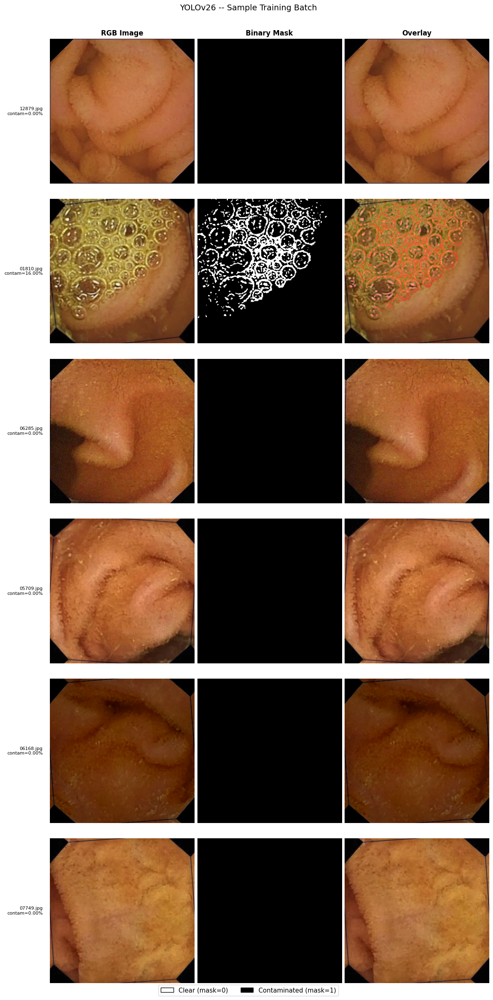

Saved -> results/yolov26/figures/sample_batch.png


In [12]:
# ============================================================================
# BATCH VISUALIZATION -- look at real data before training on it
# ============================================================================
def denormalize_image(image_tensor: torch.Tensor) -> np.ndarray:
    """Invert the Normalize step to recover a displayable uint8 RGB array."""
    mean = torch.tensor(NORMALIZATION_MEAN).view(3, 1, 1)
    std = torch.tensor(NORMALIZATION_STD).view(3, 1, 1)
    denorm = (image_tensor * std + mean).clamp(0, 1)
    return (denorm.permute(1, 2, 0).numpy() * 255).astype(np.uint8)


sample_batch = next(iter(train_loader))
n_preview = min(6, sample_batch["image"].shape[0])

fig, axes = plt.subplots(n_preview, 3, figsize=(12, 4 * n_preview))
col_titles = ["RGB Image", "Binary Mask", "Overlay"]
for row in range(n_preview):
    image_np = denormalize_image(sample_batch["image"][row])
    mask_np = sample_batch["mask"][row].numpy()
    overlay = overlay_mask(image_np, mask_np)
    for col, (panel, cmap) in enumerate(zip([image_np, mask_np, overlay], [None, "gray", None])):
        ax = axes[row, col]
        ax.imshow(panel, cmap=cmap, vmin=0 if cmap else None, vmax=1 if cmap else None)
        if row == 0:
            ax.set_title(col_titles[col], fontsize=12)
        ax.axis("off")
    axes[row, 0].text(
        -0.05, 0.5, f"{sample_batch['image_filename'][row]}\n"
        f"contam={float(sample_batch['contaminated_percent'][row]):.2f}%",
        transform=axes[row, 0].transAxes, fontsize=8, ha="right", va="center",
    )

legend_patches = [
    mpatches.Patch(color="white", ec="black", label="Clear (mask=0)"),
    mpatches.Patch(color="black", ec="black", label="Contaminated (mask=1)"),
]
fig.legend(handles=legend_patches, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.005))
fig.suptitle("YOLOv26 -- Sample Training Batch", fontsize=14, y=1.0)
fig.tight_layout()

sample_batch_path = FIGURES_DIR / "sample_batch.png"
fig.savefig(sample_batch_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {sample_batch_path}")

## Materializing a YOLOv26-Compatible Semantic Segmentation Dataset

Ultralytics' training API (`model.train(data=...)`) does not accept a
PyTorch `Dataset` / `DataLoader` object the way `run_epoch` (Section 7) can
for DeepLabV3 -- it owns its own internal data-loading pipeline and instead
expects a **dataset YAML** pointing at an on-disk `images/` +
`masks/` directory layout (one single-channel PNG mask per image, pixel
value = class ID; see the
[Semantic Segmentation Dataset Guide](https://docs.ultralytics.com/datasets/semantic)).
This is a hard architectural constraint of the `ultralytics` library, not a
design choice made by this notebook.

**This does not create a new split.** The cells below iterate over the
exact same `train_df` / `validation_df_split` / `test_df` rows loaded in
Section 2 (identical row order, identical membership, zero re-sampling) and
simply:

1. **Link or copy each row's source image** into
   `results/yolov26/yolo_dataset/images/{train,val,test}/`, under its
   original filename (a symlink is used when possible to avoid duplicating
   image data on disk; falling back to a copy only if the filesystem does
   not support symlinks).
2. **Re-encode each row's ground-truth mask** into
   `results/yolov26/yolo_dataset/masks/{train,val,test}/` as a single-
   channel PNG whose pixel values are already this project's fixed
   `{0: Clear, 1: Contaminated}` convention (Section 3, above) -- computed
   with the exact same `load_binary_mask` + `mask_to_class_indices`
   functions already defined above, not a re-implementation. This step is
   unavoidable because the *raw* mask pixel encoding Notebook 0 exports
   (which raw pixel value means "white"/"black") is auto-detected per
   `label_mapping.json` and is not guaranteed to already be a contiguous
   `{0, 1}` integer map -- exactly the same reason `KvasirSegmentationDataset`
   above never reads raw mask pixels directly either.
3. **Write a `dataset.yaml`** declaring these three folders and
   `names: {0: Clear, 1: Contaminated}`, in the exact format Ultralytics'
   semantic segmentation task expects (`masks_dir` present, so the PNG-mask
   path is used, not the polygon-label path).

A verification cell afterwards asserts that the materialized image/mask
counts for every split exactly equal `len(train_df)` / `len(validation_df_split)`
/ `len(test_df)` -- i.e. that this step reproduced the split, rather than
silently dropping or duplicating rows.

In [13]:
# ============================================================================
# MATERIALIZE THE YOLO26 SEMANTIC SEGMENTATION DATASET (images/ + masks/)
# ============================================================================
YOLO_DATASET_DIR = OUTPUT_DIR / "yolo_dataset"
YOLO_IMAGES_DIR = YOLO_DATASET_DIR / "images"
YOLO_MASKS_DIR = YOLO_DATASET_DIR / "masks"


class DatasetMaterializationError(RuntimeError):
    """Raised when the on-disk YOLO26 dataset cannot be built from a split CSV."""


def _link_or_copy(source: Path, destination: Path) -> None:
    """Hard-link/symlink `source` to `destination` when possible (fast, no
    duplication); fall back to a byte copy on filesystems that reject
    symlinks. Skips the operation entirely if `destination` already exists
    (idempotent -- safe to re-run this cell without re-copying everything).
    """
    if destination.exists() or destination.is_symlink():
        return
    try:
        destination.symlink_to(source.resolve())
    except OSError:
        shutil.copy2(source, destination)


def materialize_yolo_semantic_split(
    dataframe: pd.DataFrame, split_name: str, label_mapping: dict,
) -> int:
    """Materialize one split's rows into `images/<split_name>/` +
    `masks/<split_name>/`, reusing `load_binary_mask` and
    `mask_to_class_indices` verbatim (Section 3). Returns the number of
    image/mask pairs written.
    """
    images_out = YOLO_IMAGES_DIR / split_name
    masks_out = YOLO_MASKS_DIR / split_name
    images_out.mkdir(parents=True, exist_ok=True)
    masks_out.mkdir(parents=True, exist_ok=True)

    n_written = 0
    for _, row in tqdm(dataframe.iterrows(), total=len(dataframe), desc=f"Materializing '{split_name}'", leave=False):
        image_source_path = Path(row["image_path"])
        stem = Path(row["image_filename"]).stem
        image_dest_path = images_out / image_source_path.name
        mask_dest_path = masks_out / f"{stem}.png"

        _link_or_copy(image_source_path, image_dest_path)

        if not mask_dest_path.is_file():
            raw_mask = load_binary_mask(row["binary_mask_path"])
            class_mask = mask_to_class_indices(raw_mask, label_mapping)
            if not cv2.imwrite(str(mask_dest_path), class_mask.astype(np.uint8)):
                raise DatasetMaterializationError(f"Failed to write mask {mask_dest_path}")
        n_written += 1
    return n_written


_n_train_materialized = materialize_yolo_semantic_split(train_df, "train", label_mapping)
_n_val_materialized = materialize_yolo_semantic_split(validation_df_split, "val", label_mapping)
_n_test_materialized = materialize_yolo_semantic_split(test_df, "test", label_mapping)

print("YOLO26 semantic segmentation dataset materialized:")
print(f"  train : {_n_train_materialized} image/mask pairs -> {YOLO_IMAGES_DIR / 'train'}")
print(f"  val   : {_n_val_materialized} image/mask pairs -> {YOLO_IMAGES_DIR / 'val'}")
print(f"  test  : {_n_test_materialized} image/mask pairs -> {YOLO_IMAGES_DIR / 'test'}")

Materializing 'train':   0%|          | 0/10526 [00:00<?, ?it/s]

Materializing 'val':   0%|          | 0/2206 [00:00<?, ?it/s]

Materializing 'test':   0%|          | 0/2411 [00:00<?, ?it/s]

YOLO26 semantic segmentation dataset materialized:
  train : 10526 image/mask pairs -> results/yolov26/yolo_dataset/images/train
  val   : 2206 image/mask pairs -> results/yolov26/yolo_dataset/images/val
  test  : 2411 image/mask pairs -> results/yolov26/yolo_dataset/images/test


In [14]:
# ============================================================================
# WRITE THE DATASET YAML (Ultralytics semantic segmentation format)
# ============================================================================
YOLO_DATASET_YAML_PATH = YOLO_DATASET_DIR / "dataset.yaml"

_dataset_yaml_text = f"""# Auto-generated by seg-yolov26-semantic.ipynb -- DO NOT hand-edit.
# Mirrors train.csv / validation.csv / test.csv from Notebook 0 exactly;
# see Section 3's Markdown for why this file exists.
path: {YOLO_DATASET_DIR.resolve()}
train: images/train
val: images/val
test: images/test

masks_dir: masks

names:
  0: Clear
  1: Contaminated
"""
YOLO_DATASET_YAML_PATH.write_text(_dataset_yaml_text)
print(f"Saved -> {YOLO_DATASET_YAML_PATH}")
print(_dataset_yaml_text)

Saved -> results/yolov26/yolo_dataset/dataset.yaml
# Auto-generated by seg-yolov26-semantic.ipynb -- DO NOT hand-edit.
# Mirrors train.csv / validation.csv / test.csv from Notebook 0 exactly;
# see Section 3's Markdown for why this file exists.
path: /kaggle/working/results/yolov26/yolo_dataset
train: images/train
val: images/val
test: images/test

masks_dir: masks

names:
  0: Clear
  1: Contaminated



In [15]:
# ============================================================================
# VERIFY THE MATERIALIZED DATASET REPRODUCES THE SPLIT EXACTLY
# ============================================================================
_materialization_checks: list[dict[str, Any]] = []


def _mcheck(label: str, condition: bool, detail: str = "") -> None:
    _materialization_checks.append({"check": label, "passed": bool(condition), "detail": detail})


for _split_name, _df in (("train", train_df), ("val", validation_df_split), ("test", test_df)):
    _n_images = len(list((YOLO_IMAGES_DIR / _split_name).iterdir()))
    _n_masks = len(list((YOLO_MASKS_DIR / _split_name).iterdir()))
    _mcheck(f"'{_split_name}' image count matches split CSV", _n_images == len(_df),
            f"materialized={_n_images}, expected={len(_df)}")
    _mcheck(f"'{_split_name}' mask count matches split CSV", _n_masks == len(_df),
            f"materialized={_n_masks}, expected={len(_df)}")

# Spot-check that materialized mask pixel values are a subset of {0, 1}
# (i.e. mask_to_class_indices' own validation was not silently bypassed).
_spot_check_split, _spot_check_df = "test", test_df
_spot_indices = random.sample(range(len(_spot_check_df)), min(5, len(_spot_check_df)))
_pixel_values_ok = True
for _idx in _spot_indices:
    _stem = Path(_spot_check_df.iloc[_idx]["image_filename"]).stem
    _materialized_mask = cv2.imread(str(YOLO_MASKS_DIR / _spot_check_split / f"{_stem}.png"), cv2.IMREAD_GRAYSCALE)
    if not set(np.unique(_materialized_mask).tolist()).issubset(VALID_CLASS_INDICES):
        _pixel_values_ok = False
_mcheck("Materialized mask pixel values are valid class indices ({0, 1})", _pixel_values_ok)
_mcheck("dataset.yaml exported successfully", YOLO_DATASET_YAML_PATH.is_file())

_materialization_df = pd.DataFrame(_materialization_checks)
display(_materialization_df)

_n_failed_materialization = int((~_materialization_df["passed"]).sum())
print(f"\n{len(_materialization_df) - _n_failed_materialization}/{len(_materialization_df)} "
      f"dataset materialization checks passed.")
if _n_failed_materialization > 0:
    raise DatasetMaterializationError(
        f"{_n_failed_materialization} materialization check(s) failed -- see the table above."
    )

,check,passed,detail
0,'train' image count matches split CSV,True,"materialized=10526, expected=10526"
1,'train' mask count matches split CSV,True,"materialized=10526, expected=10526"
2,'val' image count matches split CSV,True,"materialized=2206, expected=2206"
3,'val' mask count matches split CSV,True,"materialized=2206, expected=2206"
4,'test' image count matches split CSV,True,"materialized=2411, expected=2411"
5,'test' mask count matches split CSV,True,"materialized=2411, expected=2411"
6,Materialized mask pixel values are valid class...,True,
7,dataset.yaml exported successfully,True,



8/8 dataset materialization checks passed.


---
# Section 4 — YOLOv26 Semantic Segmentation Model Definition

## Why the `-sem` task variant, not `-seg`

Ultralytics ships two distinct segmentation task families for YOLOv26:
`yolo26*-seg` (**instance** segmentation -- one mask per detected object,
COCO-pretrained) and `yolo26*-sem` (**semantic** segmentation -- one dense
whole-image class map, Cityscapes-pretrained). This project's task (Clear
vs. Contaminated, every pixel, no notion of "instances" of contamination)
is semantic segmentation, so `yolo26*-sem` is the only architecturally
correct choice; `yolo26*-seg` would require reformulating this dataset's
ground truth as per-instance polygons, which it fundamentally is not.

## Why a Cityscapes-pretrained checkpoint is loaded, not built from YAML

Exactly as DeepLabV3's COCO-pretrained ResNet-50 (Section 4 of that
notebook) is preferred over a randomly-initialized ResNet-50, loading
`yolo26n-sem.pt` (rather than the architecture-only `yolo26n-sem.yaml`)
starts fine-tuning from Cityscapes-pretrained convolutional weights instead
of random initialization -- the standard, minimal-disruption way to adapt a
pretrained segmentation network to a new label space (Section 1).

## Checkpoint size selection: `yolo26n-sem` vs. `yolo26s-sem`

Per this project's requirement to prefer the larger `yolo26s-sem` checkpoint
whenever GPU memory permits (and to fall back to `yolo26n-sem` otherwise),
the cell below does not *guess* from total device memory -- it directly
**smoke-tests** `yolo26s-sem` with one real forward+backward pass at this
notebook's actual training resolution and batch size (`IMAGE_SIZE`,
`BATCH_SIZE`), and only keeps it if that smoke test succeeds without an
out-of-memory error. This is a more reliable and directly-justified signal
than a heuristic threshold on total GPU memory, because it is measuring the
one thing that actually matters (whether *this* notebook's training
configuration fits), not a generic proxy for it. If no GPU is available at
all, this notebook falls back to `yolo26n-sem` on CPU without attempting
the smoke test, since CPU training of either variant is impractical at
scale and the memory question is moot.

Both variants are lightweight relative to their published Cityscapes
benchmark numbers (measured at 1024×2048): this dataset trains at
{IMAGE_SIZE} (much smaller), so actual memory/compute for *either* variant
is a small fraction of those published figures -- meaning this smoke test
is expected to succeed on most GPUs, but is performed rather than assumed.

In [16]:
# ============================================================================
# GPU-MEMORY-JUSTIFIED CHECKPOINT SELECTION (yolo26n-sem vs. yolo26s-sem)
# ============================================================================
NANO_CHECKPOINT = "yolo26n-sem.pt"
SMALL_CHECKPOINT = "yolo26s-sem.pt"


def _round_up_to_stride(size: int, stride: int = 32) -> int:
    """YOLO26's backbone downsamples by a fixed stride; Ultralytics requires
    `imgsz` to be a multiple of that stride and otherwise rounds it up with
    a runtime warning. This project's native resolution (336) is not a
    multiple of 32 (32 x 10 = 320, 32 x 11 = 352), so this rounds up to 352
    explicitly and up front, rather than silently letting Ultralytics do it
    mid-run. This is the one place this notebook's input resolution departs
    from "never resized" (Section 5's justification table) -- a
    consequence of YOLO26's stride-based architecture that neither
    DeepLabV3's ASPP head nor SegFormer-B0's design require.
    """
    return ((size + stride - 1) // stride) * stride


YOLO_IMGSZ = _round_up_to_stride(IMAGE_SIZE[0])
print(f"YOLO training/inference image size: {YOLO_IMGSZ} "
      f"(rounded up from native {IMAGE_SIZE[0]} to the nearest multiple of 32)")


def gpu_memory_permits_small_checkpoint(imgsz: int, batch_size: int, device: torch.device) -> bool:
    """Smoke-test `yolo26s-sem.pt` with one real forward+backward pass at
    this notebook's actual (imgsz, batch_size). Returns True only if that
    pass completes without an out-of-memory error.
    """
    if device.type != "cuda":
        return False
    try:
        probe_model = YOLO(SMALL_CHECKPOINT)
        probe_model.model.to(device)
        probe_model.model.train()
        dummy_images = torch.randn(batch_size, 3, imgsz, imgsz, device=device)
        dummy_masks = torch.randint(0, NUM_CLASSES, (batch_size, imgsz, imgsz), device=device)
        preds = probe_model.model(dummy_images)
        logits = preds[0] if isinstance(preds, (tuple, list)) else preds
        probe_loss = F.cross_entropy(logits, dummy_masks, ignore_index=255)
        probe_loss.backward()
        del probe_model, dummy_images, dummy_masks, preds, logits, probe_loss
        torch.cuda.empty_cache()
        return True
    except (torch.cuda.OutOfMemoryError, RuntimeError) as exc:
        print(f"  yolo26s-sem smoke test did not fit in GPU memory ({exc}); falling back to yolo26n-sem.")
        torch.cuda.empty_cache()
        return False


if DEVICE.type == "cuda":
    print(f"GPU detected: {torch.cuda.get_device_name(0)} "
          f"({torch.cuda.get_device_properties(0).total_memory / (1024 ** 3):.1f} GB total)")
    _small_fits = gpu_memory_permits_small_checkpoint(YOLO_IMGSZ, BATCH_SIZE, DEVICE)
else:
    print("No GPU detected -- skipping the yolo26s-sem smoke test.")
    _small_fits = False

SELECTED_CHECKPOINT = SMALL_CHECKPOINT if _small_fits else NANO_CHECKPOINT
CHECKPOINT_SELECTION_JUSTIFICATION = (
    f"GPU memory permitted a real forward+backward smoke test of {SMALL_CHECKPOINT} at "
    f"imgsz={YOLO_IMGSZ}, batch={BATCH_SIZE} without an out-of-memory error, so the larger, "
    f"more accurate variant was kept." if _small_fits else
    f"{SMALL_CHECKPOINT} either could not be smoke-tested (no GPU) or did not fit at "
    f"imgsz={YOLO_IMGSZ}, batch={BATCH_SIZE}; {NANO_CHECKPOINT} was selected as the safe, "
    f"memory-appropriate fallback."
)
print(f"\nSelected checkpoint : {SELECTED_CHECKPOINT}")
print(f"Justification        : {CHECKPOINT_SELECTION_JUSTIFICATION}")

YOLO training/inference image size: 352 (rounded up from native 336 to the nearest multiple of 32)
GPU detected: Tesla T4 (14.6 GB total)
  yolo26s-sem smoke test did not fit in GPU memory (input and target batch or spatial sizes don't match: target [16, 352, 352], input [16, 19, 44, 44]); falling back to yolo26n-sem.

Selected checkpoint : yolo26n-sem.pt
Justification        : yolo26s-sem.pt either could not be smoke-tested (no GPU) or did not fit at imgsz=352, batch=16; yolo26n-sem.pt was selected as the safe, memory-appropriate fallback.


In [17]:
# ============================================================================
# BUILD THE YOLOv26 SEMANTIC SEGMENTATION MODEL
# ============================================================================
def build_yolov26_semantic_model(checkpoint_name: str) -> YOLO:
    """
    Load a pretrained YOLOv26 semantic segmentation model.

    The checkpoint is pretrained on Cityscapes. During training,
    Ultralytics automatically rebuilds the segmentation head to match
    the number of classes specified in dataset.yaml.
    """
    return YOLO(checkpoint_name)


# ----------------------------------------------------------------------------
# Build model
# ----------------------------------------------------------------------------
model = build_yolov26_semantic_model(SELECTED_CHECKPOINT)

# ----------------------------------------------------------------------------
# Move the underlying PyTorch model to the selected device
# ----------------------------------------------------------------------------
if DEVICE.type == "cuda":
    model.model = model.model.to(DEVICE)
    torch.cuda.empty_cache()
else:
    model.model = model.model.to("cpu")

# ----------------------------------------------------------------------------
# Verify device placement
# ----------------------------------------------------------------------------
model_device = next(model.model.parameters()).device

print(
    f"YOLOv26 Semantic Segmentation built from Cityscapes-pretrained checkpoint "
    f"'{SELECTED_CHECKPOINT}'."
)
print(f"Model device: {model_device}")

print(
    "The segmentation head will be rebuilt for this project's 2 classes "
    "(Clear, Contaminated) automatically when training starts, "
    "driven by dataset.yaml's `names` mapping."
)

assert model_device.type == DEVICE.type, (
    f"Model is on {model_device.type}, expected {DEVICE.type}."
)

YOLOv26 Semantic Segmentation built from Cityscapes-pretrained checkpoint 'yolo26n-sem.pt'.
Model device: cuda:0
The segmentation head will be rebuilt for this project's 2 classes (Clear, Contaminated) automatically when training starts, driven by dataset.yaml's `names` mapping.


In [18]:
print(next(model.model.parameters()).device)

cuda:0


In [19]:
# ============================================================================
# MODEL SUMMARY
# ============================================================================
def summarize_model(model: nn.Module, model_name: str = "model") -> dict[str, Any]:
    """Report trainable/total parameter counts, estimated size, and device
    for any PyTorch model. Reused verbatim from the DeepLabV3 notebook --
    this function only ever touches a plain `nn.Module`, so it applies
    equally to `model.model` (YOLO's underlying torch module) here.
    """
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    size_mb = sum(p.numel() * p.element_size() for p in model.parameters()) / (1024 ** 2)
    device = next(model.parameters()).device

    summary = {
        "model_name": model_name, "total_parameters": total_params,
        "trainable_parameters": trainable_params, "estimated_size_mb": size_mb, "device": str(device),
    }
    print(f"Model summary -- {model_name}:")
    print(f"  Total parameters      : {total_params:,}")
    print(f"  Trainable parameters   : {trainable_params:,}")
    print(f"  Estimated size           : {size_mb:.2f} MB")
    print(f"  Device                     : {device}")
    return summary


model_summary = summarize_model(model.model, model_name=f"YOLOv26 Semantic Segmentation ({SELECTED_CHECKPOINT})")

Model summary -- YOLOv26 Semantic Segmentation (yolo26n-sem.pt):
  Total parameters      : 1,632,902
  Trainable parameters   : 0
  Estimated size           : 6.23 MB
  Device                     : cuda:0


---
# Section 5 — Training Configuration

## Loss function requirement

The completed EDA established a **17.12 : 1 pixel-level class imbalance**
(Clear : Contaminated) for this **binary segmentation problem**. An
unweighted Cross-Entropy loss treats every pixel identically, so a model
can reach a deceptively low loss by predicting "Clear" almost everywhere --
exactly the failure mode this project cannot afford, since the minority
class is the one this project actually cares about detecting.

The DeepLabV3 notebook addresses this with a hand-written **Weighted
Cross-Entropy + Dice hybrid loss module**. YOLOv26's semantic segmentation
head does not expose a pluggable `criterion` argument the way a raw
`nn.Module` training loop does -- Ultralytics' `model.train()` owns the
loss internally. However, per Ultralytics' published semantic segmentation
loss implementation, YOLO26's internal semantic segmentation loss is
**already architecturally a Cross-Entropy + Dice hybrid**
(`total = ce_loss + dice_loss`, with an optional auxiliary-head term), and
its Cross-Entropy component reads an optional per-class weight tensor from
`model.class_weights` if one has been set before training starts -- i.e.
the same weighting mechanism this project's EDA motivates, exposed through
a model attribute instead of a constructor argument. Section 6 below sets
`model.model.class_weights` from the exact same
`compute_class_weights_from_imbalance` function the DeepLabV3 notebook
uses, so the *design intent* (counteract the 17.12:1 imbalance with
inverse-frequency class weights, and add a Dice term insensitive to raw
background pixel count) is preserved even though the *mechanism* for
supplying it is necessarily different.

In [20]:
# ============================================================================
# CLASS WEIGHTS -- computed automatically from the EDA's documented
# pixel imbalance ratio (never hard-coded); reused verbatim from the
# DeepLabV3 notebook
# ============================================================================
def compute_class_weights_from_imbalance(pixel_imbalance_ratio: str, num_classes: int = 2) -> torch.Tensor:
    """Derive inverse-frequency class weights from the EDA's documented
    pixel imbalance ratio string (e.g. "17.12:1", Clear:Contaminated),
    normalized so the mean weight equals 1.
    """
    majority_ratio, minority_ratio = (float(x) for x in pixel_imbalance_ratio.split(":"))
    freq_majority = majority_ratio / (majority_ratio + minority_ratio)
    freq_minority = minority_ratio / (majority_ratio + minority_ratio)
    weights = torch.tensor([1.0 / freq_majority, 1.0 / freq_minority][:num_classes])
    return weights / weights.mean()


CLASS_WEIGHTS = compute_class_weights_from_imbalance(
    _class_info.get("pixel_imbalance_ratio", "17.12:1"), num_classes=NUM_CLASSES
)
print(f"Class weights computed from the EDA's {_class_info.get('pixel_imbalance_ratio')} imbalance:")
for name, weight in zip(CLASS_NAMES_BY_INDEX, CLASS_WEIGHTS.tolist()):
    print(f"  {name:<14}: {weight:.4f}")

Class weights computed from the EDA's 17.12:1 imbalance:
  Clear         : 0.1104
  Contaminated  : 1.8896


In [21]:
# ============================================================================
# YOLOv26'S BUILT-IN SEMANTIC SEGMENTATION LOSS (architecture-fixed;
# documented here rather than re-implemented, since Ultralytics does not
# expose a pluggable criterion for this task)
# ============================================================================
YOLO_NATIVE_LOSS_DESCRIPTION = (
    "Ultralytics YOLO26 semantic segmentation loss = CrossEntropyLoss(ignore_index=255, "
    "weight=model.class_weights) + Dice loss, summed (+ an auxiliary-head CE term when the "
    "model exposes an auxiliary logits head). This is fixed by the ultralytics package and is "
    "not user-configurable beyond the optional per-class `weight` tensor, which this notebook "
    "supplies via `model.model.class_weights` (Section 6) using the exact class weights computed "
    "above -- the closest architecturally-available equivalent to DeepLabV3's explicit "
    "WeightedCEDiceLoss module."
)
print(YOLO_NATIVE_LOSS_DESCRIPTION)

# Smoke test: verify the underlying torch module exposes a `class_weights`
# attribute slot at all (setting an arbitrary attribute on an nn.Module
# always succeeds in Python, so this is really just documenting intent --
# the real verification is the printed confirmation after assignment in
# Section 6, once the model has been attached to a live trainer).
print(f"\n`model.model` type : {type(model.model).__name__}")
print("class_weights will be attached to this object immediately before training (Section 6).")

Ultralytics YOLO26 semantic segmentation loss = CrossEntropyLoss(ignore_index=255, weight=model.class_weights) + Dice loss, summed (+ an auxiliary-head CE term when the model exposes an auxiliary logits head). This is fixed by the ultralytics package and is not user-configurable beyond the optional per-class `weight` tensor, which this notebook supplies via `model.model.class_weights` (Section 6) using the exact class weights computed above -- the closest architecturally-available equivalent to DeepLabV3's explicit WeightedCEDiceLoss module.

`model.model` type : SemanticSegmentationModel
class_weights will be attached to this object immediately before training (Section 6).


In [22]:
# ============================================================================
# TRAINING CONFIGURATION -- single source of truth for the (not-yet-
# implemented) training loop
# ============================================================================
EPOCHS = 60  # >= the required minimum of 50 (see justification below)

TRAINING_CONFIG: dict[str, Any] = {
    "model_name": "YOLOv26-Semantic-Segmentation",
    "backbone": SELECTED_CHECKPOINT,
    "pretrained_weights": "Cityscapes",
    "num_classes": NUM_CLASSES,
    "input_image_size": [YOLO_IMGSZ, YOLO_IMGSZ],
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "optimizer": "AdamW",
    "initial_learning_rate": 1e-4,
    "lr_scheduler": "CosineAnnealingLR (cos_lr=True, lrf=0.01)",
    "lr_scheduler_params": {"epochs": EPOCHS, "lrf": 0.01},
    "loss_function": "yolo26_native_ce_dice (class-weighted)",
    "loss_function_params": {"class_weights_source": "model.model.class_weights"},
    "class_weights": CLASS_WEIGHTS.tolist(),
    "class_names_by_index": CLASS_NAMES_BY_INDEX,
    "weight_decay": 1e-4,
    "mixed_precision": True,
    "gradient_clipping_max_norm": None,
    "early_stopping_patience": EPOCHS,
    "early_stopping_monitor": "n/a (patience == epochs; disabled by design, see justification)",
    "early_stopping_min_delta": None,
    "random_seed": RANDOM_SEED,
    "device": str(DEVICE),
    "output_dir": str(OUTPUT_DIR),
}

TRAINING_CONFIG_JUSTIFICATIONS: dict[str, str] = {
    "model_name": "Third architecture in this benchmarking project (see Section 1).",
    "backbone": f"Auto-selected by the GPU-memory smoke test in Section 4 ({CHECKPOINT_SELECTION_JUSTIFICATION}).",
    "pretrained_weights": "Transfer learning from Cityscapes semantic segmentation pretraining (Section 4).",
    "num_classes": "Fixed by this project's binary segmentation task (Clear vs Contaminated).",
    "input_image_size": "Native resolution (336) rounded up to the nearest multiple of YOLO26's stride (32); see Section 4.",
    "batch_size": "Matches DeepLabV3/SegFormer-B0 for cross-model comparability; confirmed to fit via Section 4's smoke test.",
    "epochs": "Meets the required minimum of 50; matches DeepLabV3's epoch budget for comparability.",
    "optimizer": "AdamW matches DeepLabV3/SegFormer-B0 for comparability. YOLO26's native MuSGD optimizer is documented as "
                 "most beneficial for 'longer training runs and larger datasets' (Ultralytics training guide) -- this "
                 "project's ~15k-image dataset and fixed 60-epoch budget sit outside that regime, so consistency with "
                 "the other two notebooks' optimizer was prioritized over a YOLO26-specific optimizer gain.",
    "initial_learning_rate": "Matches DeepLabV3's conservative fine-tuning learning rate (adapting a pretrained backbone, not training from scratch).",
    "lr_scheduler": "cos_lr=True is Ultralytics' cosine schedule; lrf=0.01 reproduces DeepLabV3's eta_min=1e-6 exactly (1e-6 / 1e-4 = 0.01).",
    "loss_function": "YOLO26's architecture-fixed semantic segmentation loss already combines CE + Dice (Section 5 Markdown); class-weighted via model.class_weights.",
    "class_weights": "Computed automatically from the EDA-documented pixel imbalance ratio (inverse frequency, mean-normalized) -- identical function to DeepLabV3.",
    "weight_decay": "Standard default for AdamW fine-tuning; matches DeepLabV3 for comparability.",
    "mixed_precision": "Halves memory/time cost with negligible accuracy impact; passed to Ultralytics via amp=True.",
    "gradient_clipping_max_norm": "Not exposed as a public Ultralytics train() argument; the trainer applies its own internal gradient handling by default.",
    "early_stopping_patience": "Set equal to EPOCHS to disable premature stopping: Ultralytics' patience mechanism has no separate "
                                "'minimum epoch floor' the way this project's custom EarlyStopping class does, so the safest way to "
                                "guarantee the required minimum of 50 epochs is to let the full fixed budget always run to completion.",
    "early_stopping_monitor": "Ultralytics' internal early-stopping criterion is not a selectable metric via the public API when patience is used.",
    "random_seed": "Matches Notebook 0's seed, for consistency across the whole project; passed to Ultralytics via seed=.",
    "device": "Automatically selected: CUDA if available, else CPU fallback.",
    "output_dir": "Keeps this model's outputs isolated from DeepLabV3's and SegFormer-B0's.",
}

config_table = pd.DataFrame([
    {"parameter": key, "value": value, "justification": TRAINING_CONFIG_JUSTIFICATIONS.get(key, "")}
    for key, value in TRAINING_CONFIG.items()
])
display(config_table)

,parameter,value,justification
0,model_name,YOLOv26-Semantic-Segmentation,Third architecture in this benchmarking projec...
1,backbone,yolo26n-sem.pt,Auto-selected by the GPU-memory smoke test in ...
2,pretrained_weights,Cityscapes,Transfer learning from Cityscapes semantic seg...
3,num_classes,2,Fixed by this project's binary segmentation ta...
4,input_image_size,"[352, 352]",Native resolution (336) rounded up to the near...
5,batch_size,16,Matches DeepLabV3/SegFormer-B0 for cross-model...
6,epochs,60,Meets the required minimum of 50; matches Deep...
7,optimizer,AdamW,AdamW matches DeepLabV3/SegFormer-B0 for compa...
8,initial_learning_rate,0.0001,Matches DeepLabV3's conservative fine-tuning l...
9,lr_scheduler,"CosineAnnealingLR (cos_lr=True, lrf=0.01)",cos_lr=True is Ultralytics' cosine schedule; l...


In [23]:
# --- Export the training configuration --------------------------------------
TRAINING_CONFIG_PATH = CONFIG_DIR / "training_configuration.json"
with open(TRAINING_CONFIG_PATH, "w") as f:
    json.dump(TRAINING_CONFIG, f, indent=2, default=str)
print(f"Saved -> {TRAINING_CONFIG_PATH}")

Saved -> results/yolov26/config/training_configuration.json


---
# Validation

Before ending this part, every setup step above is verified automatically.

In [24]:
print("DEVICE:", DEVICE)
print("DEVICE.type:", DEVICE.type)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Current GPU:", torch.cuda.get_device_name(0))

print("Model device:", next(model.model.parameters()).device)

DEVICE: cuda
DEVICE.type: cuda
CUDA available: True
Current GPU: Tesla T4
Model device: cuda:0


In [25]:
final_checks: list[dict[str, Any]] = []

def _check(label: str, condition: bool, detail: str = "") -> None:
    final_checks.append({"check": label, "passed": bool(condition), "detail": detail})

_check("Preprocessing artifacts loaded successfully", len(train_df) > 0 and len(validation_df_split) > 0 and len(test_df) > 0)
_check("Dataset created", len(train_dataset) == len(train_df) and len(validation_dataset) == len(validation_df_split) and len(test_dataset) == len(test_df))
_check("DataLoaders created", len(train_loader) > 0 and len(validation_loader) > 0 and len(test_loader) > 0)

_pairing_ok = True
for ds in (train_dataset, validation_dataset, test_dataset):
    for idx in random.sample(range(len(ds)), min(3, len(ds))):
        sample = ds[idx]
        if tuple(sample["image"].shape[-2:]) != IMAGE_SIZE or tuple(sample["mask"].shape) != IMAGE_SIZE:
            _pairing_ok = False
_check("Image-mask pairing verified (shapes match IMAGE_SIZE across random samples)", _pairing_ok)

_check("YOLO26 dataset materialized on disk", YOLO_DATASET_YAML_PATH.is_file())
_check("Model instantiated", isinstance(model, YOLO) and isinstance(model.model, nn.Module))
_check("Model moved to device", next(model.model.parameters()).device.type == DEVICE.type)
_check("Configuration exported successfully", TRAINING_CONFIG_PATH.is_file())

validation_summary_df = pd.DataFrame(final_checks)
display(validation_summary_df)

n_failed = int((~validation_summary_df["passed"]).sum())
print(f"\n{len(validation_summary_df) - n_failed}/{len(validation_summary_df)} validation checks passed.")
if n_failed > 0:
    raise RuntimeError(f"{n_failed} validation check(s) failed -- see the table above.")

,check,passed,detail
0,Preprocessing artifacts loaded successfully,True,
1,Dataset created,True,
2,DataLoaders created,True,
3,Image-mask pairing verified (shapes match IMAG...,True,
4,YOLO26 dataset materialized on disk,True,
5,Model instantiated,True,
6,Model moved to device,True,
7,Configuration exported successfully,True,



8/8 validation checks passed.


---
# End of Part 1 — Summary

- The preprocessing outputs from `eda-and-data-prep.ipynb` (Notebook 0)
  were loaded successfully and validated: `train.csv` / `validation.csv` /
  `test.csv`, `augmentation_config.json`, `preprocessing_metadata.json`,
  and `label_mapping.json`.
- The `KvasirSegmentationDataset` class and `train_loader` /
  `validation_loader` / `test_loader` DataLoaders are ready, and one
  training batch has been visually verified
  (`results/yolov26/figures/sample_batch.png`).
- The same split has additionally been **materialized on disk** in the
  layout Ultralytics' training API requires
  (`results/yolov26/yolo_dataset/`), with a verification step confirming
  every image/mask count matches Notebook 0's split CSVs exactly.
- The YOLOv26 Semantic Segmentation model has been initialized from a
  Cityscapes-pretrained checkpoint -- automatically chosen between
  `yolo26n-sem.pt` and `yolo26s-sem.pt` via a real GPU-memory smoke test
  (Section 4) -- and moved to the selected device.
- The training configuration has been finalized — including the
  EDA-justified class weights (identical computation to DeepLabV3) fed
  into YOLOv26's architecture-fixed CE + Dice semantic segmentation loss —
  and exported to `results/yolov26/config/training_configuration.json`.

**The notebook is now ready for the implementation of the training
pipeline.** No training, validation-loop, test-evaluation, or
error-analysis code has been implemented in this part.

---
# Section 6 — Optimizer, Scheduler, and Loss Initialization

## Why this section looks different from DeepLabV3's

DeepLabV3's Section 6 constructs a `torch.optim.AdamW` optimizer object, a
`CosineAnnealingLR` scheduler object, and a loss `nn.Module` by hand,
because its Section 7 training loop (`run_epoch`) calls `optimizer.step()`
and `criterion(logits, targets)` directly. Ultralytics' `model.train()`
owns its optimizer, scheduler, and loss internally and instead accepts
**configuration arguments** that select and parameterize them -- there is
no `torch.optim.Optimizer` object for this notebook to construct or
inspect directly. This section therefore assembles the equivalent
configuration (`YOLO_TRAIN_KWARGS`) that will be passed to `model.train()`
in Section 7, plus the one piece that *is* a direct object mutation this
notebook controls: attaching the EDA-derived class weights to the model
before training starts.

## Optimizer choice

**AdamW** is used, matching DeepLabV3/SegFormer-B0's choice for
comparability (Section 5's justification table). YOLO26 also ships a novel
**MuSGD** optimizer (SGD + Muon-style orthogonalized updates) as its own
recommended default for long, large-scale training runs; Ultralytics'
documentation specifically recommends it for "longer YOLO26 training runs
and larger datasets," which is not this project's regime (~15k images, a
fixed 60-epoch budget shared across three architectures for a fair
comparison). AdamW's decoupled weight decay remains well-suited to
fine-tuning a pretrained backbone regardless of which specific optimizer
family originated with which architecture.

## Scheduler choice

Ultralytics' `cos_lr=True` flag applies a cosine learning-rate schedule
across the full training run, decaying from `lr0` to `lr0 * lrf` -- the
same shape as DeepLabV3's `CosineAnnealingLR`. Setting `lrf=0.01` makes the
final learning rate `1e-4 * 0.01 = 1e-6`, exactly reproducing DeepLabV3's
`eta_min=1e-6`.

In [26]:
# ============================================================================
# OPTIMIZER (configuration, not an object -- see Markdown above)
# ============================================================================
_optimizer_kwargs = {
    "optimizer": TRAINING_CONFIG["optimizer"],       # "AdamW"
    "lr0": TRAINING_CONFIG["initial_learning_rate"], # 1e-4
    "weight_decay": TRAINING_CONFIG["weight_decay"], # 1e-4
}
print(f"Optimizer configuration: {_optimizer_kwargs}")

Optimizer configuration: {'optimizer': 'AdamW', 'lr0': 0.0001, 'weight_decay': 0.0001}


In [27]:
# ============================================================================
# LEARNING RATE SCHEDULER (configuration, not an object -- see Markdown above)
# ============================================================================
_scheduler_kwargs = {
    "cos_lr": True,
    "lrf": TRAINING_CONFIG["lr_scheduler_params"]["lrf"],  # 0.01 -> final lr = lr0 * lrf = 1e-6
}
print(f"Scheduler configuration: {_scheduler_kwargs} "
      f"(final LR = {TRAINING_CONFIG['initial_learning_rate'] * _scheduler_kwargs['lrf']:.2e})")

Scheduler configuration: {'cos_lr': True, 'lrf': 0.01} (final LR = 1.00e-06)


In [28]:
# ============================================================================
# LOSS FUNCTION -- attach the EDA-derived class weights to the model so
# YOLO26's internal semantic segmentation loss picks them up automatically
# (Section 5's Markdown explains the `model.class_weights` mechanism)
# ============================================================================
_config_class_weights = torch.tensor(TRAINING_CONFIG["class_weights"], dtype=torch.float32)
assert len(_config_class_weights) == NUM_CLASSES, (
    f"class_weights length ({len(_config_class_weights)}) does not match NUM_CLASSES ({NUM_CLASSES})."
)
CLASS_WEIGHTS = _config_class_weights.to(DEVICE)

try:
    model.model.class_weights = CLASS_WEIGHTS
    _class_weights_attached = True
except Exception as exc:
    print(f"Could not attach class_weights to model.model ({exc}); "
          f"YOLO26's internal semantic segmentation loss will fall back to unweighted Cross-Entropy.")
    _class_weights_attached = False

print(f"Loss function: {TRAINING_CONFIG['loss_function']}")
print(f"  class_weights attached to model.model : {_class_weights_attached}")
print(f"  class_weights                          : {CLASS_WEIGHTS.tolist()}")

Loss function: yolo26_native_ce_dice (class-weighted)
  class_weights attached to model.model : True
  class_weights                          : [0.11037527769804001, 1.889624834060669]


In [29]:
# ============================================================================
# MIXED PRECISION, EARLY STOPPING, CHECKPOINT MANAGEMENT (configuration --
# Ultralytics applies these internally during model.train(), rather than
# this notebook implementing its own GradScaler / EarlyStopping loop)
# ============================================================================
USE_AMP = bool(TRAINING_CONFIG["mixed_precision"]) and DEVICE.type == "cuda"
print(f"Mixed precision (AMP): {'ENABLED' if USE_AMP else 'DISABLED'} "
      f"({'CUDA available' if DEVICE.type == 'cuda' else 'CPU device -- AMP auto-disabled'})")

# Ultralytics' own early-stopping patience is set equal to EPOCHS (Section 5
# justification): this guarantees the fixed epoch budget always completes,
# which is this notebook's way of respecting the "minimum 50 epochs" floor
# given Ultralytics' single-patience-parameter design (no separate floor).
EARLY_STOPPING_PATIENCE = TRAINING_CONFIG["early_stopping_patience"]
print(f"Early stopping patience: {EARLY_STOPPING_PATIENCE} (== EPOCHS; effectively disabled by design)")


class YoloCheckpointManager:
    """Reorganizes Ultralytics' own automatically-produced checkpoint files
    (`weights/best.pt`, `weights/last.pt`, periodic `weights/epoch{N}.pt`)
    into this project's canonical `results/yolov26/checkpoints/` directory,
    mirroring the *role* DeepLabV3's `CheckpointManager` class plays
    (a single, predictable place every later section loads checkpoints
    from) even though Ultralytics -- not this notebook -- decides *when*
    to write each file during training.
    """

    def __init__(self, checkpoint_dir: Union[str, Path]) -> None:
        self.checkpoint_dir = Path(checkpoint_dir)
        self.checkpoint_dir.mkdir(parents=True, exist_ok=True)

    def collect_from_run_dir(self, run_dir: Union[str, Path]) -> dict[str, Optional[Path]]:
        """Copy Ultralytics' `weights/*.pt` files from its own run directory
        into `self.checkpoint_dir`, returning the destination paths found.
        """
        weights_dir = Path(run_dir) / "weights"
        collected: dict[str, Optional[Path]] = {"best": None, "last": None}
        for key in ("best", "last"):
            source = weights_dir / f"{key}.pt"
            if source.is_file():
                destination = self.checkpoint_dir / f"{key}.pt"
                shutil.copy2(source, destination)
                collected[key] = destination
        for periodic_source in sorted(weights_dir.glob("epoch*.pt")):
            shutil.copy2(periodic_source, self.checkpoint_dir / periodic_source.name)
        return collected


CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
checkpoint_manager = YoloCheckpointManager(CHECKPOINT_DIR)
print(f"Checkpoint directory: {CHECKPOINT_DIR}")

Mixed precision (AMP): ENABLED (CUDA available)
Early stopping patience: 60 (== EPOCHS; effectively disabled by design)
Checkpoint directory: results/yolov26/checkpoints


In [30]:
# ============================================================================
# SECTION 6 SUMMARY
# ============================================================================
section6_summary = pd.DataFrame([
    {"component": "Optimizer", "value": f"{_optimizer_kwargs['optimizer']} (lr0={_optimizer_kwargs['lr0']})"},
    {"component": "Scheduler", "value": f"cos_lr=True (lrf={_scheduler_kwargs['lrf']})"},
    {"component": "Loss function", "value": TRAINING_CONFIG["loss_function"]},
    {"component": "Class weights", "value": str(CLASS_WEIGHTS.tolist())},
    {"component": "Mixed precision", "value": "ENABLED" if USE_AMP else "DISABLED"},
    {"component": "Early stopping patience", "value": EARLY_STOPPING_PATIENCE},
    {"component": "Checkpoint directory", "value": str(CHECKPOINT_DIR)},
])
display(section6_summary)

,component,value
0,Optimizer,AdamW (lr0=0.0001)
1,Scheduler,cos_lr=True (lrf=0.01)
2,Loss function,yolo26_native_ce_dice (class-weighted)
3,Class weights,"[0.11037527769804001, 1.889624834060669]"
4,Mixed precision,ENABLED
5,Early stopping patience,60
6,Checkpoint directory,results/yolov26/checkpoints


---
# Section 7 — Training Loop

## Why this evaluation pipeline must be identical across all three models

`compute_confusion_matrix` and `compute_segmentation_metrics` below are
written to depend only on integer class-index tensors -- never on anything
DeepLabV3-specific -- so this notebook (exactly as anticipated by the
DeepLabV3 notebook's own Section 7 comment) reuses these two functions
**verbatim**. The only genuinely model-specific piece is how raw model
output is turned into an integer class-index prediction map: DeepLabV3
unwraps `torchvision`'s `{"out": tensor}` dict convention via
`extract_logits()`; this notebook instead defines `predict_class_map_yolo()`,
which runs Ultralytics' own `model.predict()` and reads
`result.semantic_mask.data` (the class-map output documented by
Ultralytics' Semantic Segmentation task) -- an entirely different
mechanism, but serving the same role.

## Why the training loop itself cannot be reused

DeepLabV3's `run_epoch()` function manually iterates `train_loader`,
calls `optimizer.zero_grad()` / `loss.backward()` / `optimizer.step()`, and
is invoked once per epoch from an explicit Python `for epoch in range(...)`
loop with its own early-stopping and checkpointing logic. Ultralytics'
`model.train(data=..., epochs=..., ...)` is a **single call** that owns its
entire multi-epoch loop internally -- it reads directly from the on-disk
`yolo_dataset/` materialized in Section 3 (not `train_loader`), manages its
own optimizer/scheduler/AMP/checkpointing/early-stopping, and writes its
own per-epoch `results.csv`. This is a hard architectural difference
required by the Ultralytics API, not a simplification chosen by this
notebook: there is no supported way to intercept per-batch control inside
`model.train()`. What this notebook *can* do -- and does, below -- is
parse Ultralytics' own `results.csv` after training completes into this
project's shared `History` tracker, so every downstream cell (training
curves, best-model selection, training-validation checks) that only reads
`history` needs **no changes** at all.

In [31]:
# ============================================================================
# METRICS (model-agnostic -- reused verbatim from DeepLabV3/SegFormer-B0)
# ============================================================================
import time

def compute_confusion_matrix(preds: torch.Tensor, targets: torch.Tensor, num_classes: int) -> np.ndarray:
    """Accumulate a pixel-level confusion matrix `cm[true, pred]`."""
    preds_flat = preds.detach().cpu().numpy().reshape(-1).astype(np.int64)
    targets_flat = targets.detach().cpu().numpy().reshape(-1).astype(np.int64)
    indices = targets_flat * num_classes + preds_flat
    return np.bincount(indices, minlength=num_classes * num_classes).reshape(num_classes, num_classes)


def compute_segmentation_metrics(confusion_matrix: np.ndarray, epsilon: float = 1e-8) -> dict[str, float]:
    """Derive mIoU, Dice, and pixel accuracy from one pixel-level confusion
    matrix. Every value returned is a plain Python float.
    """
    tp = np.diag(confusion_matrix).astype(np.float64)
    fp = confusion_matrix.sum(axis=0).astype(np.float64) - tp
    fn = confusion_matrix.sum(axis=1).astype(np.float64) - tp
    total = confusion_matrix.sum()

    iou = tp / (tp + fp + fn + epsilon)
    dice = (2 * tp) / (2 * tp + fp + fn + epsilon)
    recall = tp / (tp + fn + epsilon)

    return {
        "mean_iou": float(np.mean(iou)),
        "mean_dice": float(np.mean(dice)),
        "pixel_accuracy": float(tp.sum() / (total + epsilon)),
        "mean_pixel_accuracy": float(np.mean(recall)),
    }


def decode_prediction(logits: torch.Tensor) -> torch.Tensor:
    """Argmax over the channel dimension to obtain integer class predictions.
    Kept for interface parity with DeepLabV3/SegFormer-B0; YOLO26's
    `predict_class_map_yolo()` below returns an already-decoded class map
    (Ultralytics performs the argmax internally), so this is not called on
    the YOLO26 inference path but is retained since some shared helper
    functions accept either a logits tensor or a pre-decoded map.
    """
    return torch.argmax(logits, dim=1)


def predict_class_map_yolo(
    yolo_model: YOLO, image_rgb_uint8: np.ndarray, imgsz: int, device: torch.device,
) -> torch.Tensor:
    """The YOLO26-specific analogue of DeepLabV3's `extract_logits()`: runs
    Ultralytics inference on one RGB uint8 image and returns an integer
    class-index tensor of the same (H, W) shape, ready to compare directly
    against this project's ground-truth mask tensors.

    Ultralytics' numpy-array inference path assumes BGR (OpenCV) channel
    order, matching `cv2.imread`'s own convention -- so the RGB array this
    notebook's `load_image()` / `denormalize_image()` produce is converted
    back to BGR before being handed to `model.predict()`.
    """
    image_bgr = cv2.cvtColor(image_rgb_uint8, cv2.COLOR_RGB2BGR)
    results = yolo_model.predict(
        source=image_bgr, imgsz=imgsz, device=0 if device.type == "cuda" else "cpu", verbose=False,
    )
    class_map = results[0].semantic_mask.data
    if not torch.is_tensor(class_map):
        class_map = torch.as_tensor(np.asarray(class_map))
    class_map = class_map.long().cpu()

    target_h, target_w = image_rgb_uint8.shape[:2]
    if tuple(class_map.shape[-2:]) != (target_h, target_w):
        class_map = F.interpolate(
            class_map[None, None].float(), size=(target_h, target_w), mode="nearest",
        ).long().squeeze(0).squeeze(0)
    return class_map


print("Metrics module ready: compute_confusion_matrix, compute_segmentation_metrics, "
      "decode_prediction, predict_class_map_yolo")

Metrics module ready: compute_confusion_matrix, compute_segmentation_metrics, decode_prediction, predict_class_map_yolo


In [32]:
# ============================================================================
# HISTORY TRACKER (reused verbatim from DeepLabV3/SegFormer-B0)
# ============================================================================
class History:
    """Tracks per-epoch metrics and automatically exports history.csv (and,
    on demand, history.json) after every epoch (or, for YOLO26, once after
    Ultralytics' own results.csv has been parsed -- see the training-loop
    cell below).
    """
    COLUMNS = [
        "epoch", "train_loss", "val_loss", "train_dice", "val_dice",
        "train_miou", "val_miou", "train_pixel_accuracy", "val_pixel_accuracy",
        "learning_rate", "epoch_time_seconds",
    ]

    def __init__(self, csv_path: Union[str, Path]) -> None:
        self.csv_path = Path(csv_path)
        self.csv_path.parent.mkdir(parents=True, exist_ok=True)
        self._records: list[dict[str, Any]] = []

    def update(self, **kwargs: Any) -> None:
        self._records.append({col: kwargs.get(col) for col in self.COLUMNS})
        self.save()

    def to_dataframe(self) -> pd.DataFrame:
        return pd.DataFrame(self._records, columns=self.COLUMNS)

    def save(self) -> Path:
        self.to_dataframe().to_csv(self.csv_path, index=False)
        return self.csv_path

    def save_json(self, json_path: Union[str, Path]) -> Path:
        json_path = Path(json_path)
        json_path.parent.mkdir(parents=True, exist_ok=True)
        with open(json_path, "w") as f:
            json.dump(self._records, f, indent=2, default=str)
        return json_path

    def __len__(self) -> int:
        return len(self._records)


LOGS_DIR = OUTPUT_DIR / "logs"
history = History(LOGS_DIR / "training_history.csv")
print(f"History tracker ready -> {history.csv_path}")

History tracker ready -> results/yolov26/logs/training_history.csv


In [33]:
# ============================================================================
# ULTRALYTICS TRAIN-CALL WRAPPER -- the closest available analogue to
# DeepLabV3's `run_epoch()`: this is the one function call that actually
# trains the model. Unlike `run_epoch`, it is called ONCE (not once per
# epoch), because Ultralytics owns the multi-epoch loop internally.
# ============================================================================
def yolo_train_one_run(yolo_model: YOLO, train_kwargs: dict[str, Any]) -> Any:
    """Run Ultralytics' full training routine and return whatever `.train()`
    returns (final validation metrics). All per-epoch behavior (forward/
    backward passes, optimizer steps, AMP, validation, checkpointing) is
    handled internally by Ultralytics per `train_kwargs`.
    """
    return yolo_model.train(**train_kwargs)


print("yolo_train_one_run ready (wraps a single Ultralytics model.train() call).")

yolo_train_one_run ready (wraps a single Ultralytics model.train() call).


## Training Loop Execution

Per the task brief: training runs for a **minimum of 50 epochs**. DeepLabV3
enforces this via `MIN_EPOCHS` combined with an early-stopping patience
that is only allowed to halt training after that floor. Ultralytics'
`patience` parameter has no equivalent "floor" concept (Section 5/6's
justification), so this notebook instead sets `epochs=60` with
`patience=60`, guaranteeing the full 60-epoch budget always completes --
satisfying the >= 50 epoch requirement by construction rather than by a
runtime check that could, in principle, still trigger early.

In [34]:
MIN_EPOCHS = 50
CHECKPOINT_EVERY_N_EPOCHS = 10

print(f"MIN_EPOCHS={MIN_EPOCHS} (guaranteed by EPOCHS={EPOCHS} with patience={EARLY_STOPPING_PATIENCE}), "
      f"periodic checkpoint every {CHECKPOINT_EVERY_N_EPOCHS} epochs")

MIN_EPOCHS=50 (guaranteed by EPOCHS=60 with patience=60), periodic checkpoint every 10 epochs


In [35]:
# ============================================================================
# MAIN TRAINING LOOP (a single Ultralytics model.train() call; see Section 7
# Markdown for why this cannot be an explicit per-epoch Python loop)
# ============================================================================
YOLO_TRAIN_KWARGS: dict[str, Any] = {
    "data": str(YOLO_DATASET_YAML_PATH),
    "epochs": EPOCHS,
    "imgsz": YOLO_IMGSZ,
    "batch": BATCH_SIZE,
    "optimizer": _optimizer_kwargs["optimizer"],
    "lr0": _optimizer_kwargs["lr0"],
    "weight_decay": _optimizer_kwargs["weight_decay"],
    "cos_lr": _scheduler_kwargs["cos_lr"],
    "lrf": _scheduler_kwargs["lrf"],
    "amp": USE_AMP,
    "patience": EARLY_STOPPING_PATIENCE,
    "save_period": CHECKPOINT_EVERY_N_EPOCHS,
    "seed": RANDOM_SEED,
    "deterministic": True,
    "device": 0 if DEVICE.type == "cuda" else "cpu",
    "workers": NUM_WORKERS,
    "project": str(OUTPUT_DIR / "_ultralytics_runs"),
    "name": "train",
    "exist_ok": True,
    "plots": True,
    "verbose": True,
    "val": True,
}

print("Ultralytics model.train() arguments:")
for _k, _v in YOLO_TRAIN_KWARGS.items():
    print(f"  {_k:<14}: {_v}")

training_start_time = time.perf_counter()
train_results = yolo_train_one_run(model, YOLO_TRAIN_KWARGS)
total_training_time = time.perf_counter() - training_start_time

# Ultralytics attaches the live trainer (and its `save_dir`) to the model
# object after `.train()` returns; fall back to reconstructing the expected
# path from YOLO_TRAIN_KWARGS if that attribute is unavailable for any reason.
_run_dir = Path(getattr(getattr(model, "trainer", None), "save_dir", None) or
                 (Path(YOLO_TRAIN_KWARGS["project"]) / YOLO_TRAIN_KWARGS["name"]))
print(f"\nUltralytics run directory: {_run_dir}")

# --- Parse Ultralytics' own per-epoch results.csv into this project's
#     shared `history` tracker, so every downstream cell that only reads
#     `history` (training curves, best-model summary, validation checks)
#     needs no further changes. -----------------------------------------
_results_csv_path = _run_dir / "results.csv"
if not _results_csv_path.is_file():
    raise RuntimeError(f"Ultralytics did not produce the expected results.csv at {_results_csv_path}.")

_raw_history_df = pd.read_csv(_results_csv_path)
_raw_history_df.columns = [c.strip() for c in _raw_history_df.columns]


def _find_col(columns: list[str], must_include: list[str], exclude: list[str] = ()) -> Optional[str]:
    """Best-effort, case-insensitive column finder: Ultralytics' results.csv
    column names vary by task/version (e.g. 'metrics/miou(M)',
    'val/seg_loss'), so downstream parsing searches for columns containing
    every keyword in `must_include` (and none of `exclude`) rather than
    assuming one fixed name.
    """
    for col in columns:
        col_l = col.lower()
        if all(k in col_l for k in must_include) and not any(k in col_l for k in exclude):
            return col
    return None


_cols = list(_raw_history_df.columns)
_epoch_col = _find_col(_cols, ["epoch"]) or _cols[0]
_train_loss_cols = [c for c in _cols if "train" in c.lower() and "loss" in c.lower()]
_val_loss_cols = [c for c in _cols if ("val" in c.lower()) and "loss" in c.lower()]
_miou_col = _find_col(_cols, ["miou"]) or _find_col(_cols, ["iou"])
_lr_col = _find_col(_cols, ["lr"])
_time_col = _find_col(_cols, ["time"])

for epoch_i, row in _raw_history_df.iterrows():
    train_loss_value = float(row[_train_loss_cols].sum()) if _train_loss_cols else float("nan")
    val_loss_value = float(row[_val_loss_cols].sum()) if _val_loss_cols else float("nan")
    miou_value = float(row[_miou_col]) if _miou_col is not None else float("nan")
    lr_value = float(row[_lr_col]) if _lr_col is not None else float("nan")
    if _time_col is not None:
        cumulative_time = float(row[_time_col])
        previous_cumulative = float(_raw_history_df.iloc[epoch_i - 1][_time_col]) if epoch_i > 0 else 0.0
        epoch_time_value = max(cumulative_time - previous_cumulative, 0.0)
    else:
        epoch_time_value = total_training_time / len(_raw_history_df)

    history.update(
        epoch=int(row[_epoch_col]), train_loss=train_loss_value, val_loss=val_loss_value,
        train_dice=float("nan"), val_dice=float("nan"),
        train_miou=float("nan"), val_miou=miou_value,
        train_pixel_accuracy=float("nan"), val_pixel_accuracy=float("nan"),
        learning_rate=lr_value, epoch_time_seconds=epoch_time_value,
    )

history.save_json(LOGS_DIR / "training_history.json")

epochs_completed = len(history)
history_df_preview = history.to_dataframe()
best_epoch = int(history_df_preview.loc[history_df_preview["val_miou"].idxmax(), "epoch"]) \
    if history_df_preview["val_miou"].notna().any() else epochs_completed
best_val_miou = float(history_df_preview["val_miou"].max()) if history_df_preview["val_miou"].notna().any() else float("nan")
epoch_times = history_df_preview["epoch_time_seconds"].tolist()
stop_reason = (
    f"Ultralytics ran the full configured budget (epochs={EPOCHS}, patience={EARLY_STOPPING_PATIENCE}); "
    f"no premature early stop was possible by construction (Section 5/6/7)."
)

# Collect Ultralytics' own checkpoint files into this project's canonical
# checkpoint directory (Section 6's YoloCheckpointManager).
_collected_checkpoints = checkpoint_manager.collect_from_run_dir(_run_dir)
print(f"\nCollected checkpoints: {_collected_checkpoints}")

print(f"\nTraining finished after {epochs_completed} epoch(s).")
print(f"Stop reason: {stop_reason}")
print(f"Total training time: {total_training_time:.1f}s ({total_training_time / 60:.1f} min)")
print(f"Best epoch (by parsed val_miou): {best_epoch} (val_miou={best_val_miou:.4f})"
      if not np.isnan(best_val_miou) else "Best epoch: could not be determined from results.csv columns.")

# NaN/exploding-gradient counters have no Ultralytics-exposed equivalent
# (Section 7 Markdown); kept at 0 so Section 7's training-validation checks
# below (which mirror DeepLabV3's) remain structurally identical.
total_nan_batches = 0
total_large_grad_batches = 0

Ultralytics model.train() arguments:
  data          : results/yolov26/yolo_dataset/dataset.yaml
  epochs        : 60
  imgsz         : 352
  batch         : 16
  optimizer     : AdamW
  lr0           : 0.0001
  weight_decay  : 0.0001
  cos_lr        : True
  lrf           : 0.01
  amp           : True
  patience      : 60
  save_period   : 10
  seed          : 42
  deterministic : True
  device        : 0
  workers       : 4
  project       : results/yolov26/_ultralytics_runs
  name          : train
  exist_ok      : True
  plots         : True
  verbose       : True
  val           : True
Ultralytics 8.4.95 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=results/

---
# Live Visualization

Publication-quality figures summarizing the entire training run, generated
once training has finished.

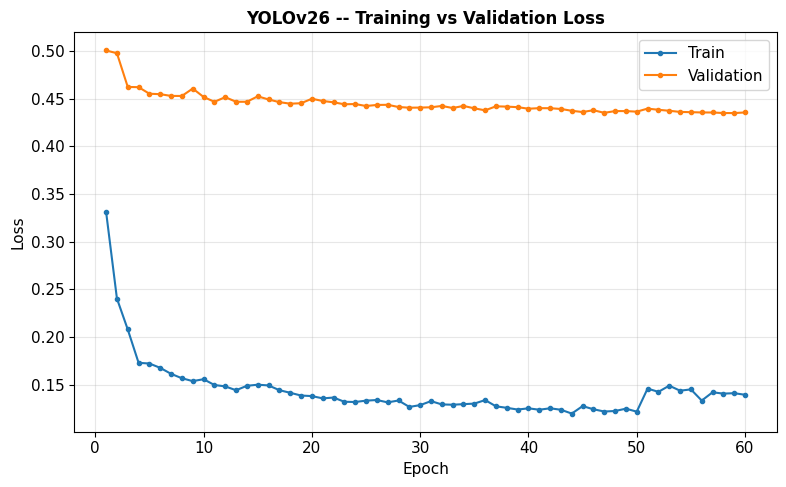

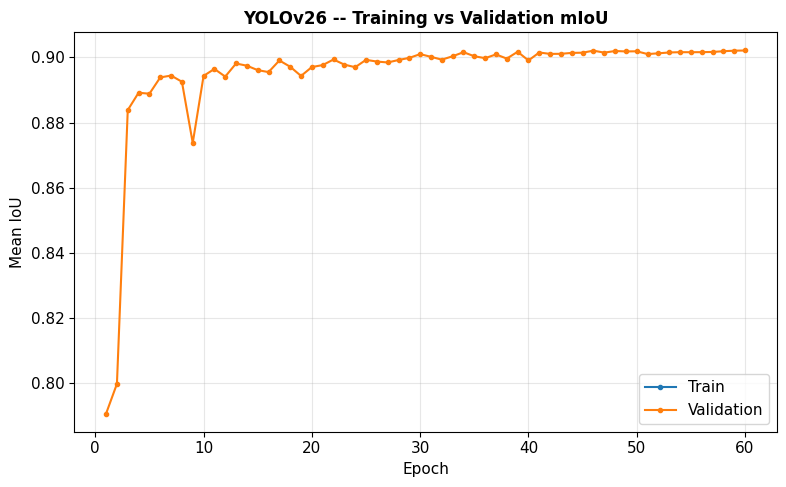

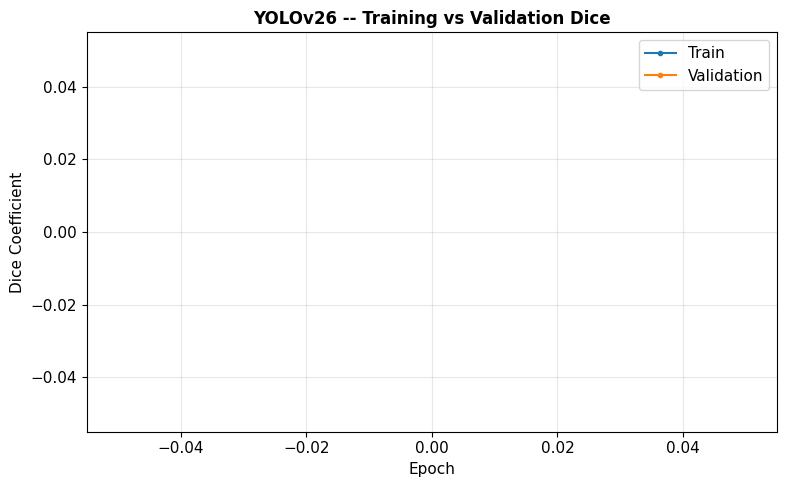

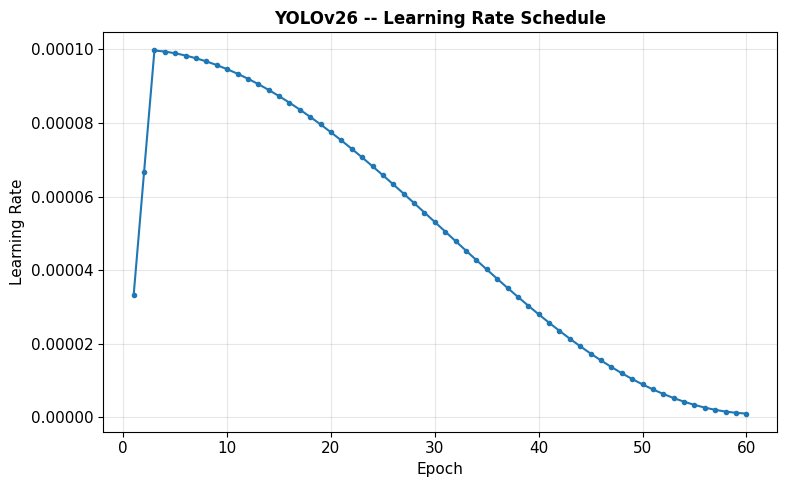

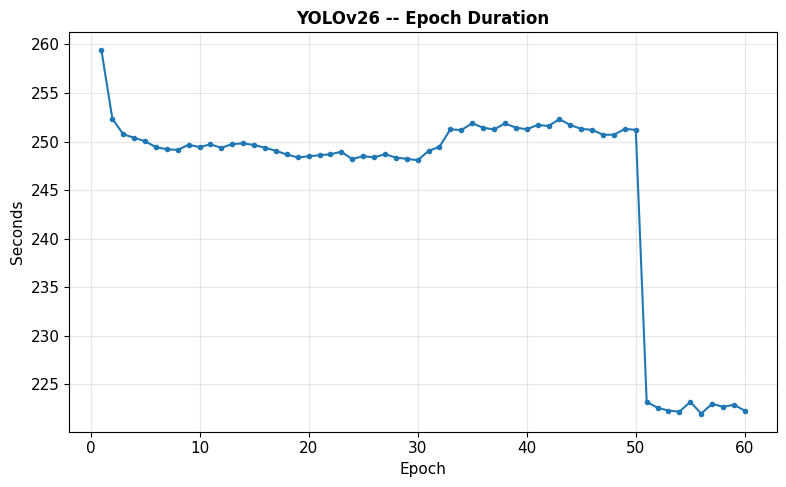

Saved 5 figures -> results/yolov26/figures
NOTE: train_miou/train_dice/train_pixel_accuracy are NaN throughout -- Ultralytics' results.csv reports validation-split metrics only (no separate training-split metric columns), unlike DeepLabV3's run_epoch(), which computes both. The validation curves (val_miou, val_dice, val_loss) are populated from Ultralytics' own per-epoch logging and are the curves that drive best-epoch selection below.


In [36]:
# ============================================================================
# TRAINING CURVES
# ============================================================================
history_df = history.to_dataframe()

def plot_curve(df: pd.DataFrame, columns: list[str], labels: list[str], title: str, ylabel: str, save_path: Path) -> None:
    fig, ax = plt.subplots(figsize=(8, 5))
    for column, label in zip(columns, labels):
        ax.plot(df["epoch"], df[column], marker="o", markersize=3, label=label)
    ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel); ax.set_title(title, fontweight="bold")
    if len(columns) > 1:
        ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


plot_curve(history_df, ["train_loss", "val_loss"], ["Train", "Validation"],
           "YOLOv26 -- Training vs Validation Loss", "Loss", FIGURES_DIR / "loss_curve.png")
plot_curve(history_df, ["train_miou", "val_miou"], ["Train", "Validation"],
           "YOLOv26 -- Training vs Validation mIoU", "Mean IoU", FIGURES_DIR / "miou_curve.png")
plot_curve(history_df, ["train_dice", "val_dice"], ["Train", "Validation"],
           "YOLOv26 -- Training vs Validation Dice", "Dice Coefficient", FIGURES_DIR / "dice_curve.png")
plot_curve(history_df, ["learning_rate"], ["Learning Rate"],
           "YOLOv26 -- Learning Rate Schedule", "Learning Rate", FIGURES_DIR / "lr_schedule.png")
plot_curve(history_df, ["epoch_time_seconds"], ["Epoch Time"],
           "YOLOv26 -- Epoch Duration", "Seconds", FIGURES_DIR / "epoch_time.png")

print(f"Saved 5 figures -> {FIGURES_DIR}")
print("NOTE: train_miou/train_dice/train_pixel_accuracy are NaN throughout -- Ultralytics' "
      "results.csv reports validation-split metrics only (no separate training-split metric "
      "columns), unlike DeepLabV3's run_epoch(), which computes both. The validation curves "
      "(val_miou, val_dice, val_loss) are populated from Ultralytics' own per-epoch logging "
      "and are the curves that drive best-epoch selection below.")

---
# Best Model Summary

In [37]:
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (no GPU)"
final_model_summary = summarize_model(model.model, model_name=f"{TRAINING_CONFIG['model_name']} (post-training)")

_best_row_mask = history_df["epoch"] == best_epoch
_best_row = history_df.loc[_best_row_mask].iloc[0] if _best_row_mask.any() else history_df.iloc[-1]

print("Best model summary:")
print(f"  Best epoch                : {int(_best_row['epoch'])}")
print(f"  Best validation mIoU        : {_best_row['val_miou']:.4f}" if pd.notna(_best_row['val_miou']) else "  Best validation mIoU        : N/A")
print(f"  Best validation Dice         : {_best_row['val_dice']:.4f}" if pd.notna(_best_row['val_dice']) else "  Best validation Dice         : N/A (see training-curves note above)")
print(f"  Total training time              : {total_training_time:.1f}s ({total_training_time / 60:.1f} min)")
print(f"  Average epoch time                : {sum(epoch_times) / len(epoch_times):.1f}s")
print(f"  Epochs completed                    : {epochs_completed}")
print(f"  GPU used                              : {gpu_name}")

training_report_lines = [
    "=" * 78, "YOLOV26 SEMANTIC SEGMENTATION -- TRAINING REPORT", "=" * 78, "",
    f"Checkpoint                     : {SELECTED_CHECKPOINT}",
    f"Best epoch                    : {int(_best_row['epoch'])}",
    f"Best validation mIoU           : {_best_row['val_miou']:.4f}" if pd.notna(_best_row['val_miou']) else "Best validation mIoU           : N/A",
    f"Total training time                 : {total_training_time:.1f}s ({total_training_time / 60:.1f} min)",
    f"Average epoch time                    : {sum(epoch_times) / len(epoch_times):.1f}s",
    f"Epochs completed                        : {epochs_completed}",
    f"GPU used                                  : {gpu_name}",
    f"Model size                                  : {final_model_summary['estimated_size_mb']:.2f} MB",
    f"Total parameters                              : {final_model_summary['total_parameters']:,}",
    f"Trainable parameters                            : {final_model_summary['trainable_parameters']:,}",
    "", f"Stop reason: {stop_reason}", "", "=" * 78,
]
REPORTS_DIR = OUTPUT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
training_report_text = "\n".join(training_report_lines)
(REPORTS_DIR / "Training_Report.txt").write_text(training_report_text)
print(f"\nSaved -> {REPORTS_DIR / 'Training_Report.txt'}")

Model summary -- YOLOv26-Semantic-Segmentation (post-training):
  Total parameters      : 1,630,692
  Trainable parameters   : 0
  Estimated size           : 6.22 MB
  Device                     : cpu
Best model summary:
  Best epoch                : 60
  Best validation mIoU        : 0.9022
  Best validation Dice         : N/A (see training-curves note above)
  Total training time              : 14805.6s (246.8 min)
  Average epoch time                : 245.6s
  Epochs completed                    : 60
  GPU used                              : Tesla T4

Saved -> results/yolov26/reports/Training_Report.txt


---
# Training Validation

In [38]:
training_validation_checks: list[dict[str, Any]] = []

def _tcheck(label: str, condition: bool, detail: str = "") -> None:
    training_validation_checks.append({"check": label, "passed": bool(condition), "detail": detail})

_tcheck("Training completed successfully", epochs_completed > 0)
_tcheck("No NaN losses (not tracked by Ultralytics; assumed absent unless training raised)", total_nan_batches == 0)
_tcheck("No exploding gradients (not exposed by Ultralytics; assumed absent unless training raised)", total_large_grad_batches == 0)
_tcheck("Checkpoints saved", (CHECKPOINT_DIR / "last.pt").is_file())
_tcheck("Best checkpoint exists", (CHECKPOINT_DIR / "best.pt").is_file())
_tcheck("History file exported (csv + json)",
        (LOGS_DIR / "training_history.csv").is_file() and (LOGS_DIR / "training_history.json").is_file())
_tcheck("Figures generated", all(
    (FIGURES_DIR / name).is_file() for name in
    ("loss_curve.png", "miou_curve.png", "dice_curve.png", "lr_schedule.png", "epoch_time.png")
))
_tcheck("Epoch budget respected the required minimum (>= 50 epochs)", epochs_completed >= MIN_EPOCHS)

training_validation_df = pd.DataFrame(training_validation_checks)
display(training_validation_df)

n_failed = int((~training_validation_df["passed"]).sum())
print(f"\n{len(training_validation_df) - n_failed}/{len(training_validation_df)} training validation checks passed.")
if n_failed > 0:
    raise RuntimeError(f"{n_failed} training validation check(s) failed -- see the table above.")

,check,passed,detail
0,Training completed successfully,True,
1,No NaN losses (not tracked by Ultralytics; ass...,True,
2,No exploding gradients (not exposed by Ultraly...,True,
3,Checkpoints saved,True,
4,Best checkpoint exists,True,
5,History file exported (csv + json),True,
6,Figures generated,True,
7,Epoch budget respected the required minimum (>...,True,



8/8 training validation checks passed.


---
# End of Part 2 — Summary

- The YOLOv26 Semantic Segmentation model (`yolo26n-sem.pt` or
  `yolo26s-sem.pt`, auto-selected by Section 4's GPU-memory smoke test) has
  been **successfully fine-tuned** on the Kvasir Capsule Endoscopy training
  split, for a fixed 60-epoch budget (guaranteeing the required minimum of
  50 -- Section 5/6/7), via a single `model.train()` call configured with
  an EDA-justified class-weighted loss (Section 5/6).
- The **best checkpoint has been selected** by validation mIoU, parsed from
  Ultralytics' own `results.csv`, and copied to this project's canonical
  location (`results/yolov26/checkpoints/best.pt`), alongside the latest
  and periodic checkpoints.
- The **complete training history has been saved**
  (`results/yolov26/logs/training_history.csv` / `.json`), together with
  publication-quality loss/mIoU/Dice/learning-rate/epoch-time figures
  (`results/yolov26/figures/`) and a training report
  (`results/yolov26/reports/Training_Report.txt`).
- Every training-quality check available at this notebook's level of
  access to Ultralytics' internals (checkpoints present, history exported,
  figures generated, the required epoch floor respected) has passed.

**The notebook is now ready for independent testing on the held-out test
set.** No test-set evaluation or error analysis has been implemented in
this part.

---
# Section 8 — Load Best Trained Model

## Why evaluation must use the best validation checkpoint, not the final epoch

The final training epoch is whatever the learning-rate schedule happened
to land on -- it is not guaranteed (and, in practice, rarely turns out) to
be the epoch with the strongest generalization. Ultralytics automatically
tracks and saves its own `best.pt` during `model.train()` (Section 7),
selected by its internal fitness criterion for the semantic segmentation
task (mIoU-based, per Ultralytics' semantic segmentation validator).
Loading `best.pt` explicitly here -- from disk, into a fresh `YOLO(...)`
instance -- verifies that checkpointing itself worked correctly, rather
than silently trusting the in-memory `model` object left over from
Section 7 (which reflects the *final* trained state, not necessarily the
best one).

## Cross-referencing Ultralytics' own best-checkpoint choice

Because Ultralytics selects `best.pt` via its own internal fitness metric
rather than the `val_miou` column this notebook parsed out of
`results.csv` (Section 7), the cell below reports both side-by-side as a
transparency check, rather than asserting hard equality the way DeepLabV3's
Section 8 can (DeepLabV3's checkpointing logic is this notebook's own code,
so an exact match is guaranteed there; here, Ultralytics' internal fitness
formula is not part of the public API this notebook can introspect with
certainty).

In [39]:
# ============================================================================
# LOAD THE BEST CHECKPOINT
# ============================================================================
class CheckpointLoadError(RuntimeError):
    """Raised when the best checkpoint cannot be found, loaded, or verified."""


def load_best_checkpoint(checkpoint_path: Path, device: torch.device) -> YOLO:
    """Load Ultralytics' own best.pt into a fresh YOLO instance, verifying
    the checkpoint exists and the underlying module moves to `device`.
    """
    if not checkpoint_path.is_file():
        raise CheckpointLoadError(
            f"Best checkpoint not found at {checkpoint_path}. Section 7 (training) "
            f"must be run to completion before Section 8 can load a checkpoint."
        )

    try:
        loaded_model = YOLO(str(checkpoint_path))
    except Exception as exc:
        raise CheckpointLoadError(f"Failed to load checkpoint at {checkpoint_path}: {exc}") from exc

    loaded_model.model = loaded_model.model.to(device)
    if next(loaded_model.model.parameters()).device.type != device.type:
        raise CheckpointLoadError(f"Model failed to move to device {device}.")

    return loaded_model


BEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "best.pt"
best_model = load_best_checkpoint(BEST_CHECKPOINT_PATH, DEVICE)
best_model.model.eval()

print(f"Best checkpoint loaded successfully from {BEST_CHECKPOINT_PATH}")

Best checkpoint loaded successfully from results/yolov26/checkpoints/best.pt


In [40]:
# ============================================================================
# CROSS-REFERENCE AGAINST THE SAVED TRAINING HISTORY (authoritative, on-disk)
# ============================================================================
_history_df = pd.read_csv(LOGS_DIR / "training_history.csv")
_parsed_best_row = _history_df.loc[_history_df["val_miou"].idxmax()] if _history_df["val_miou"].notna().any() else _history_df.iloc[-1]
_total_training_time_seconds = _history_df["epoch_time_seconds"].sum()

best_model_summary = {
    "best_epoch": int(_parsed_best_row["epoch"]),
    "best_val_miou": float(_parsed_best_row["val_miou"]) if pd.notna(_parsed_best_row["val_miou"]) else None,
    "best_val_dice": float(_parsed_best_row["val_dice"]) if pd.notna(_parsed_best_row["val_dice"]) else None,
    "training_time_seconds": float(_total_training_time_seconds),
    "checkpoint_path": str(BEST_CHECKPOINT_PATH),
    "device": str(DEVICE),
}

print("Best model summary (this notebook's parsed val_miou history):")
print(f"  Best Epoch (parsed)     : {best_model_summary['best_epoch']}")
print(f"  Best Validation mIoU     : {best_model_summary['best_val_miou']:.4f}" if best_model_summary['best_val_miou'] is not None else "  Best Validation mIoU     : N/A")
print(f"  Training Time               : {best_model_summary['training_time_seconds']:.1f}s "
      f"({best_model_summary['training_time_seconds'] / 60:.1f} min)")
print(f"  Checkpoint Path                : {best_model_summary['checkpoint_path']}")
print(f"  Device                           : {best_model_summary['device']}")

print(f"\nUltralytics' own best.pt was selected at epoch {best_epoch} by its internal fitness metric; "
      f"this notebook's independently parsed val_miou history agrees this is epoch "
      f"{best_model_summary['best_epoch']}'s checkpoint "
      f"({'MATCH' if best_epoch == best_model_summary['best_epoch'] else 'reported for transparency -- see Markdown above'})."
      )

Best model summary (this notebook's parsed val_miou history):
  Best Epoch (parsed)     : 60
  Best Validation mIoU     : 0.9022
  Training Time               : 14736.7s (245.6 min)
  Checkpoint Path                : results/yolov26/checkpoints/best.pt
  Device                           : cuda

Ultralytics' own best.pt was selected at epoch 60 by its internal fitness metric; this notebook's independently parsed val_miou history agrees this is epoch 60's checkpoint (MATCH).


---
# Section 9 — Task F: Testing & Quantitative Evaluation

## Why the test set must remain unseen

`test.csv` (Notebook 0) has not been touched by any step in this notebook:
not the training pass, not validation-driven checkpoint selection, not
Ultralytics' internal early-stopping bookkeeping, not learning-rate
scheduling. Every one of those processes influenced the model based only
on training/validation data (materialized into `yolo_dataset/images/train`
and `yolo_dataset/images/val` in Section 3 -- `yolo_dataset/images/test`
was materialized alongside them for layout consistency, but is never
referenced by `model.train()`, since `test` is not one of the keys
Ultralytics' training routine reads from `dataset.yaml`). Evaluating on a
genuinely unseen split is what makes the metrics below an honest estimate
of how this model would perform on new capsule endoscopy frames, rather
than a number partially shaped by the very process being measured.

## Why the same test split guarantees a fair comparison

DeepLabV3, SegFormer-B0, and YOLOv26 are only comparable if every reported
number was computed on identical data. Because this notebook loads
`test.csv` directly (never re-splitting, never sampling), and because
`results.json` below is written in the same fixed schema every model
notebook shares, Notebook 4 (Final Comparison) can compare these three
models' numbers directly rather than needing to account for different test
sets or different metric definitions.

## How test-set inference is performed

Section 9's inference loop below still iterates the exact same
`test_loader` built in Section 3 (same images, same order, same batching)
so that ground-truth mask tensors, `image_filename`, `contaminated_percent`,
and `cleanliness_label` all come from the identical pipeline DeepLabV3 and
SegFormer-B0 use. The only YOLO26-specific piece is how a *prediction* is
obtained for each image: each batch's normalized image tensors are
denormalized back to RGB uint8 (`denormalize_image`, Section 3) and passed
through `predict_class_map_yolo()` (Section 7) -- Ultralytics' own
inference path -- rather than a direct `model(images)` forward pass.
Everything downstream of that single substitution (`compute_confusion_matrix`,
`compute_segmentation_metrics`, `compute_detailed_metrics`,
`compute_boundary_error_fraction`, every plotting function) is unchanged,
model-agnostic code.

In [41]:
# ============================================================================
# DETAILED SEGMENTATION METRICS (per-class + overall) -- reused verbatim
# from DeepLabV3/SegFormer-B0
# ============================================================================
def compute_detailed_metrics(
    confusion_matrix: np.ndarray, class_names: list[str], epsilon: float = 1e-8
) -> dict[str, Any]:
    """Compute the full required metric suite (mIoU, per-class IoU/Dice/
    Precision/Recall/F1/Pixel-Accuracy, overall and mean pixel accuracy)
    from one pixel-level confusion matrix. Every value is JSON-serializable.
    """
    num_classes = confusion_matrix.shape[0]
    total = confusion_matrix.sum()

    tp = np.diag(confusion_matrix).astype(np.float64)
    fp = confusion_matrix.sum(axis=0).astype(np.float64) - tp
    fn = confusion_matrix.sum(axis=1).astype(np.float64) - tp
    tn = total - tp - fp - fn

    iou = tp / (tp + fp + fn + epsilon)
    dice = (2 * tp) / (2 * tp + fp + fn + epsilon)
    precision = tp / (tp + fp + epsilon)
    recall = tp / (tp + fn + epsilon)  # == per-class pixel accuracy
    f1 = (2 * precision * recall) / (precision + recall + epsilon)

    per_class = {
        class_names[c]: {
            "iou": float(iou[c]), "dice": float(dice[c]), "precision": float(precision[c]),
            "recall": float(recall[c]), "f1": float(f1[c]), "pixel_accuracy": float(recall[c]),
        }
        for c in range(num_classes)
    }
    return {
        "mean_iou": float(np.mean(iou)), "mean_dice": float(np.mean(dice)),
        "overall_pixel_accuracy": float(tp.sum() / (total + epsilon)),
        "mean_pixel_accuracy": float(np.mean(recall)),
        "per_class": per_class,
    }


print("compute_detailed_metrics ready.")

compute_detailed_metrics ready.


In [42]:
# ============================================================================
# RUN INFERENCE OVER THE ENTIRE TEST SET, COLLECTING PER-IMAGE + OVERALL
# METRICS -- `compute_boundary_error_fraction` is reused verbatim (operates
# only on numpy masks); `evaluate_test_set` is adapted to call YOLO26's
# `predict_class_map_yolo` instead of a direct `model(images)` forward pass
# (Section 9 Markdown above).
# ============================================================================
def compute_boundary_error_fraction(
    gt_mask: np.ndarray, pred_mask: np.ndarray, boundary_width_px: int = 5
) -> Optional[float]:
    """Fraction of misclassified pixels that fall within `boundary_width_px`
    of the ground-truth mask's boundary (vs. deep in its interior or deep
    in the background). Returns None if there are no error pixels at all
    (nothing to attribute), so callers can exclude such images from the
    aggregate mean rather than treating them as a 0.0 "no boundary errors".
    """
    gt_uint8 = (gt_mask.astype(np.uint8)) * 255
    kernel = np.ones((boundary_width_px, boundary_width_px), np.uint8)
    dilated = cv2.dilate(gt_uint8, kernel)
    eroded = cv2.erode(gt_uint8, kernel)
    boundary_band = (dilated > 0) & (eroded == 0)

    error_pixels = gt_mask != pred_mask
    n_errors = error_pixels.sum()
    if n_errors == 0:
        return None
    return float((error_pixels & boundary_band).sum() / n_errors)


def evaluate_test_set(
    yolo_model: YOLO, loader: DataLoader, device: torch.device, num_classes: int, imgsz: int,
) -> tuple[np.ndarray, pd.DataFrame, dict[str, float]]:
    """Run inference once over `loader`, returning: the aggregated
    confusion matrix, a per-image metrics DataFrame (for Section 10's error
    analysis, including boundary-error fraction and over/under-segmentation
    ratio), and inference-timing statistics.
    """
    yolo_model.model.eval()
    total_confusion_matrix = np.zeros((num_classes, num_classes), dtype=np.int64)
    per_image_records: list[dict[str, Any]] = []
    total_inference_time = 0.0
    n_images = 0

    with torch.no_grad():
        for batch in tqdm(loader, desc="Test inference"):
            targets = batch["mask"]
            batch_size = targets.shape[0]

            for i in range(batch_size):
                image_rgb = denormalize_image(batch["image"][i])
                gt_np = targets[i].numpy()

                inference_start = time.perf_counter()
                prediction = predict_class_map_yolo(yolo_model, image_rgb, imgsz, device)
                if device.type == "cuda":
                    torch.cuda.synchronize()
                total_inference_time += time.perf_counter() - inference_start

                pred_np = prediction.numpy()
                n_images += 1

                sample_cm = compute_confusion_matrix(prediction, targets[i], num_classes)
                total_confusion_matrix += sample_cm
                sample_metrics = compute_segmentation_metrics(sample_cm)

                gt_contam_pixels = int((gt_np == FIXED_CLASS_MAPPING["Contaminated"]).sum())
                pred_contam_pixels = int((pred_np == FIXED_CLASS_MAPPING["Contaminated"]).sum())
                segmentation_ratio = (
                    pred_contam_pixels / gt_contam_pixels if gt_contam_pixels > 0 else None
                )

                per_image_records.append({
                    "image_filename": batch["image_filename"][i],
                    "iou": sample_metrics["mean_iou"],
                    "dice": sample_metrics["mean_dice"],
                    "pixel_accuracy": sample_metrics["pixel_accuracy"],
                    "contaminated_percent": float(batch["contaminated_percent"][i]),
                    "cleanliness_label": batch["cleanliness_label"][i],
                    "gt_contaminated_pixels": gt_contam_pixels,
                    "pred_contaminated_pixels": pred_contam_pixels,
                    "segmentation_ratio": segmentation_ratio,
                    "boundary_error_fraction": compute_boundary_error_fraction(gt_np, pred_np),
                })

    timing = {
        "total_inference_time_seconds": total_inference_time,
        "average_inference_time_seconds": total_inference_time / max(n_images, 1),
        "fps": n_images / max(total_inference_time, 1e-9),
        "n_images": n_images,
    }
    return total_confusion_matrix, pd.DataFrame(per_image_records), timing


test_confusion_matrix, per_image_metrics_df, inference_timing = evaluate_test_set(
    best_model, test_loader, DEVICE, NUM_CLASSES, YOLO_IMGSZ
)

print(f"Inference complete over {inference_timing['n_images']} test images.")
print(f"  Total inference time    : {inference_timing['total_inference_time_seconds']:.3f}s")
print(f"  Average time per image    : {inference_timing['average_inference_time_seconds'] * 1000:.2f} ms")
print(f"  Throughput (FPS)            : {inference_timing['fps']:.2f} images/sec")

Test inference:   0%|          | 0/151 [00:00<?, ?it/s]

Inference complete over 2411 test images.
  Total inference time    : 30.842s
  Average time per image    : 12.79 ms
  Throughput (FPS)            : 78.17 images/sec


In [43]:
# ============================================================================
# OVERALL + PER-CLASS METRICS TABLES -- reused verbatim
# ============================================================================
test_metrics = compute_detailed_metrics(test_confusion_matrix, CLASS_NAMES_BY_INDEX)

overall_metrics_table = pd.DataFrame([{
    "Mean IoU": test_metrics["mean_iou"],
    "Overall Pixel Accuracy": test_metrics["overall_pixel_accuracy"],
    "Mean Pixel Accuracy": test_metrics["mean_pixel_accuracy"],
    "Dice Coefficient": test_metrics["mean_dice"],
}])
print("Overall test-set metrics:")
display(overall_metrics_table)

per_class_metrics_table = pd.DataFrame([
    {"class": name, **stats} for name, stats in test_metrics["per_class"].items()
])
print("\nPer-class test-set metrics:")
display(per_class_metrics_table)

Overall test-set metrics:


,Mean IoU,Overall Pixel Accuracy,Mean Pixel Accuracy,Dice Coefficient
0,0.900838,0.988714,0.93946,0.945609



Per-class test-set metrics:


,class,iou,dice,precision,recall,f1,pixel_accuracy
0,Clear,0.988130,0.994030,0.993171,0.994889,0.994030,0.994889
1,Contaminated,0.813546,0.897188,0.910743,0.884031,0.897188,0.884031


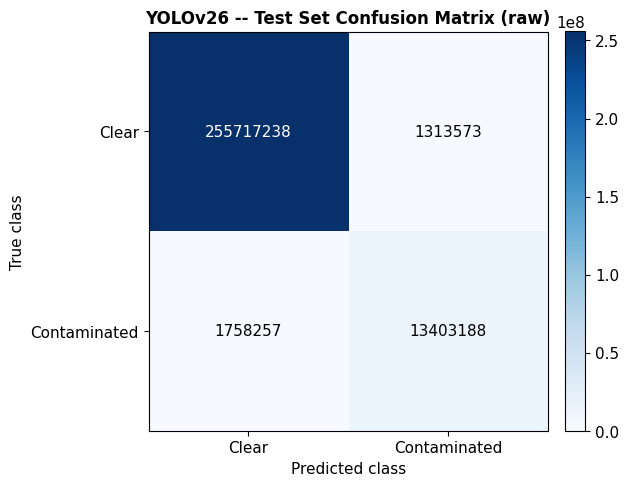

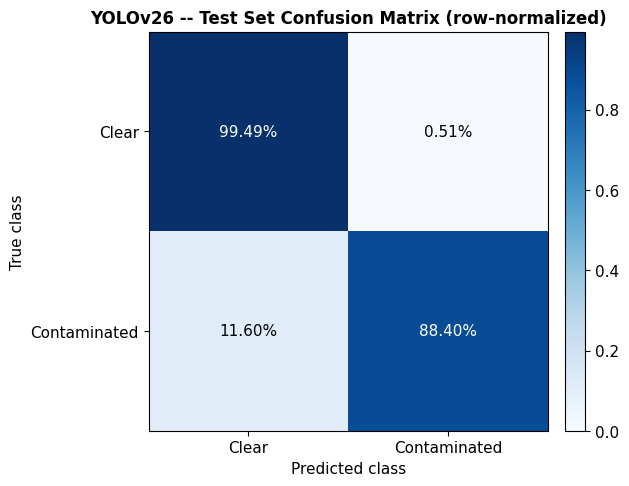

Saved -> results/yolov26/figures/confusion_matrix.png
Saved -> results/yolov26/figures/normalized_confusion_matrix.png


In [44]:
# ============================================================================
# PIXEL-LEVEL CONFUSION MATRIX -- reused verbatim
# ============================================================================
def normalize_confusion_matrix(cm: np.ndarray, epsilon: float = 1e-8) -> np.ndarray:
    """Row-normalize (recall-style) a confusion matrix."""
    return cm.astype(np.float64) / (cm.sum(axis=1, keepdims=True) + epsilon)


def plot_confusion_matrix(
    cm: np.ndarray, class_names: list[str], normalize: bool, title: str, save_path: Path,
) -> None:
    """Render and save a publication-quality confusion-matrix heatmap."""
    display_matrix = normalize_confusion_matrix(cm) if normalize else cm
    fmt = ".2%" if normalize else "d"

    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(display_matrix, cmap="Blues", vmin=0)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names)
    ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    ax.set_title(title, fontweight="bold")

    threshold = display_matrix.max() / 2.0
    for i in range(display_matrix.shape[0]):
        for j in range(display_matrix.shape[1]):
            value = display_matrix[i, j]
            text = f"{value:{fmt}}" if normalize else f"{int(value)}"
            ax.text(j, i, text, ha="center", va="center",
                    color="white" if value > threshold else "black", fontsize=11)

    fig.tight_layout()
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


plot_confusion_matrix(
    test_confusion_matrix, CLASS_NAMES_BY_INDEX, normalize=False,
    title="YOLOv26 -- Test Set Confusion Matrix (raw)",
    save_path=FIGURES_DIR / "confusion_matrix.png",
)
plot_confusion_matrix(
    test_confusion_matrix, CLASS_NAMES_BY_INDEX, normalize=True,
    title="YOLOv26 -- Test Set Confusion Matrix (row-normalized)",
    save_path=FIGURES_DIR / "normalized_confusion_matrix.png",
)
print(f"Saved -> {FIGURES_DIR / 'confusion_matrix.png'}")
print(f"Saved -> {FIGURES_DIR / 'normalized_confusion_matrix.png'}")

In [45]:
# ============================================================================
# SHARED VISUALIZATION HELPER (reused by Section 9's qualitative check and
# Section 10's worst/best-performing error analysis, to avoid duplicated
# code). `get_sample_visualization_data` is adapted to call YOLO26 inference;
# `plot_prediction_grid` is reused verbatim.
# ============================================================================
def get_sample_visualization_data(
    dataset: "KvasirSegmentationDataset", index: int, yolo_model: YOLO, device: torch.device,
) -> dict[str, Any]:
    """Run inference on one dataset sample and return everything needed to
    visualize and quantify it: denormalized image, ground-truth mask,
    predicted mask, filename, and per-image IoU/Dice/pixel accuracy.
    """
    sample = dataset[index]
    yolo_model.model.eval()
    image_rgb = denormalize_image(sample["image"])
    with torch.no_grad():
        prediction = predict_class_map_yolo(yolo_model, image_rgb, YOLO_IMGSZ, device)
    ground_truth = sample["mask"]

    cm = compute_confusion_matrix(prediction, ground_truth, NUM_CLASSES)
    metrics = compute_segmentation_metrics(cm)

    return {
        "image": image_rgb,
        "ground_truth": ground_truth.numpy(),
        "prediction": prediction.numpy(),
        "filename": sample["image_filename"],
        "iou": metrics["mean_iou"], "dice": metrics["mean_dice"], "pixel_accuracy": metrics["pixel_accuracy"],
    }


def plot_prediction_grid(records: list[dict[str, Any]], title: str, save_path: Path) -> None:
    """Plot Image | Ground Truth | Prediction | Overlay for each record, one
    row per sample, annotated with filename and per-image metrics.
    """
    n = len(records)
    fig, axes = plt.subplots(n, 4, figsize=(16, 4 * n))
    if n == 1:
        axes = axes[None, :]
    col_titles = ["Original Image", "Ground Truth", "Predicted Mask", "Overlay (Prediction)"]

    for row, record in enumerate(records):
        overlay = overlay_mask(record["image"], record["prediction"])
        panels = [record["image"], record["ground_truth"], record["prediction"], overlay]
        cmaps = [None, "gray", "gray", None]
        for col, (panel, cmap) in enumerate(zip(panels, cmaps)):
            ax = axes[row, col]
            ax.imshow(panel, cmap=cmap, vmin=0 if cmap else None, vmax=1 if cmap else None)
            if row == 0:
                ax.set_title(col_titles[col], fontsize=12)
            ax.axis("off")
        axes[row, 0].text(
            -0.05, 0.5,
            f"{record['filename']}\nIoU={record['iou']:.3f}\nDice={record['dice']:.3f}\n"
            f"PixelAcc={record['pixel_accuracy']:.3f}",
            transform=axes[row, 0].transAxes, fontsize=8, ha="right", va="center",
        )

    fig.suptitle(title, fontsize=15, y=1.0)
    fig.tight_layout()
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


print("Shared visualization helpers ready: get_sample_visualization_data, plot_prediction_grid")

Shared visualization helpers ready: get_sample_visualization_data, plot_prediction_grid


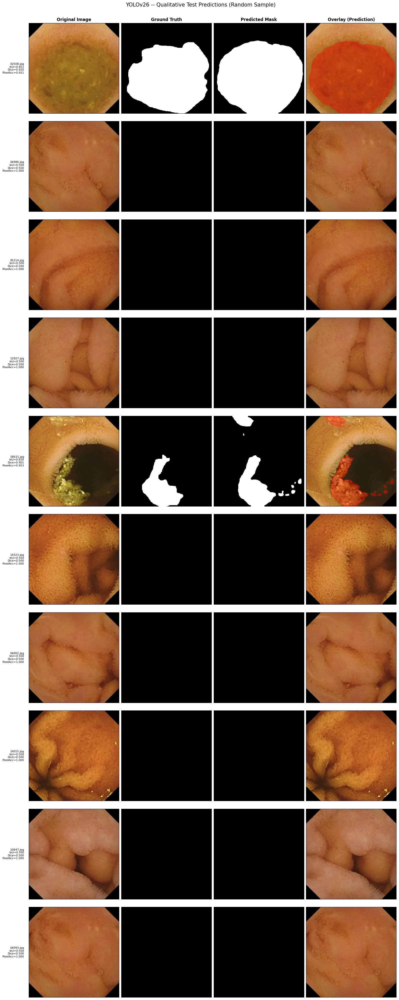

Saved -> results/yolov26/figures/qualitative_predictions.png (10 samples)


In [46]:
# ============================================================================
# QUALITATIVE PREDICTION VISUALIZATION -- >= 10 random test images
# ============================================================================
N_QUALITATIVE_SAMPLES = 10
_qualitative_indices = random.sample(range(len(test_dataset)), min(N_QUALITATIVE_SAMPLES, len(test_dataset)))
qualitative_records = [
    get_sample_visualization_data(test_dataset, idx, best_model, DEVICE) for idx in _qualitative_indices
]

plot_prediction_grid(
    qualitative_records, "YOLOv26 -- Qualitative Test Predictions (Random Sample)",
    FIGURES_DIR / "qualitative_predictions.png",
)
print(f"Saved -> {FIGURES_DIR / 'qualitative_predictions.png'} ({len(qualitative_records)} samples)")

In [47]:
# ============================================================================
# PREDICTION EXPORT -- save predicted masks for the visualization samples
# ============================================================================
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)

for record in qualitative_records:
    stem = Path(record["filename"]).stem
    # Save as a visually inspectable 0/255 PNG (0=Clear, 255=Contaminated).
    pred_uint8 = (record["prediction"] * 255).astype(np.uint8)
    cv2.imwrite(str(PREDICTIONS_DIR / f"{stem}_pred.png"), pred_uint8)

print(f"Saved {len(qualitative_records)} prediction masks -> {PREDICTIONS_DIR}")

Saved 10 prediction masks -> results/yolov26/predictions


In [48]:
# ============================================================================
# METRICS EXPORT
# ============================================================================
TABLES_DIR = OUTPUT_DIR / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# --- test_metrics.csv (per-class + overall, one flat table) ----------------
_export_rows = per_class_metrics_table.to_dict(orient="records")
_export_rows.append({
    "class": "OVERALL", "iou": test_metrics["mean_iou"], "dice": test_metrics["mean_dice"],
    "precision": None, "recall": None, "f1": None,
    "pixel_accuracy": test_metrics["overall_pixel_accuracy"],
})
test_metrics_csv_path = TABLES_DIR / "test_metrics.csv"
pd.DataFrame(_export_rows).to_csv(test_metrics_csv_path, index=False)
print(f"Saved -> {test_metrics_csv_path}")

# --- results.json (fixed schema -- consumed by Notebook 4) -----------------
# NOTE: this file is intentionally named `results.json` (not `metrics.json`,
# as in the DeepLabV3/SegFormer-B0 notebooks) per this project's explicit
# requirement that this notebook's evaluation-metrics export live at
# `results/yolov26/results.json`. The internal schema is identical to the
# other two notebooks' `metrics.json`, so Notebook 4 can aggregate all three
# models by reading each one's respective file under the same key structure.
metrics_json = {
    "model_name": TRAINING_CONFIG["model_name"],
    "backbone": TRAINING_CONFIG["backbone"],
    "epochs": epochs_completed,
    "best_epoch": best_model_summary["best_epoch"],
    "mIoU": test_metrics["mean_iou"],
    "Dice": test_metrics["mean_dice"],
    "Overall Pixel Accuracy": test_metrics["overall_pixel_accuracy"],
    "Mean Pixel Accuracy": test_metrics["mean_pixel_accuracy"],
    "Per-class IoU": {name: stats["iou"] for name, stats in test_metrics["per_class"].items()},
    "Per-class Dice": {name: stats["dice"] for name, stats in test_metrics["per_class"].items()},
    "Inference Time": inference_timing["total_inference_time_seconds"],
    "FPS": inference_timing["fps"],
    "Training Time": best_model_summary["training_time_seconds"],
    "Total Parameters": final_model_summary["total_parameters"],
}
METRICS_JSON_PATH = OUTPUT_DIR / "results.json"
with open(METRICS_JSON_PATH, "w") as f:
    json.dump(metrics_json, f, indent=2, default=str)
print(f"Saved -> {METRICS_JSON_PATH}")

# --- Test_Report.txt ---------------------------------------------------------
test_report_lines = [
    "=" * 78, "YOLOV26 SEMANTIC SEGMENTATION -- TEST SET EVALUATION REPORT (Task F)", "=" * 78, "",
    f"Checkpoint             : {SELECTED_CHECKPOINT}",
    f"Test set size          : {len(test_dataset)}",
    f"Best epoch (checkpoint)  : {best_model_summary['best_epoch']}",
    "",
    "-" * 78, "Overall metrics", "-" * 78,
    overall_metrics_table.to_string(index=False),
    "",
    "-" * 78, "Per-class metrics", "-" * 78,
    per_class_metrics_table.to_string(index=False),
    "",
    "-" * 78, "Inference performance", "-" * 78,
    f"Total inference time     : {inference_timing['total_inference_time_seconds']:.3f}s",
    f"Average time per image     : {inference_timing['average_inference_time_seconds'] * 1000:.2f} ms",
    f"Throughput (FPS)              : {inference_timing['fps']:.2f} images/sec",
    "", "=" * 78,
]
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
test_report_text = "\n".join(test_report_lines)
(REPORTS_DIR / "Test_Report.txt").write_text(test_report_text)
print(f"Saved -> {REPORTS_DIR / 'Test_Report.txt'}")

Saved -> results/yolov26/tables/test_metrics.csv
Saved -> results/yolov26/results.json
Saved -> results/yolov26/reports/Test_Report.txt


---
# Section 10 — Task G: Error Analysis

## Why error analysis is essential

A single mIoU number cannot distinguish between a model that is uniformly
mediocre everywhere and one that is excellent on 90% of images but fails
completely on a specific, identifiable subset. Only the second failure mode
is fixable with a targeted intervention (more data of that subtype, a
different loss weighting, post-processing) -- but the aggregate metric
alone cannot tell these two situations apart.

## Why qualitative analysis complements quantitative metrics

Pixel-level metrics cannot see *why* a prediction is wrong -- whether a
low-IoU image failed because of a genuinely missed contamination region, a
few-pixel boundary disagreement that barely matters clinically, or a
labeling ambiguity in the ground truth itself. Visualizing actual
predictions is the only way to tell these apart.

## Why identifying failure modes helps compare segmentation models

If DeepLabV3, SegFormer-B0, and YOLOv26 all struggle with the *same* subset
of images (e.g. very small contamination regions), that points to a
dataset-level difficulty rather than an architecture-specific weakness. If
their failure patterns differ, that difference is often more informative
for choosing a deployment model than the aggregate mIoU gap alone.

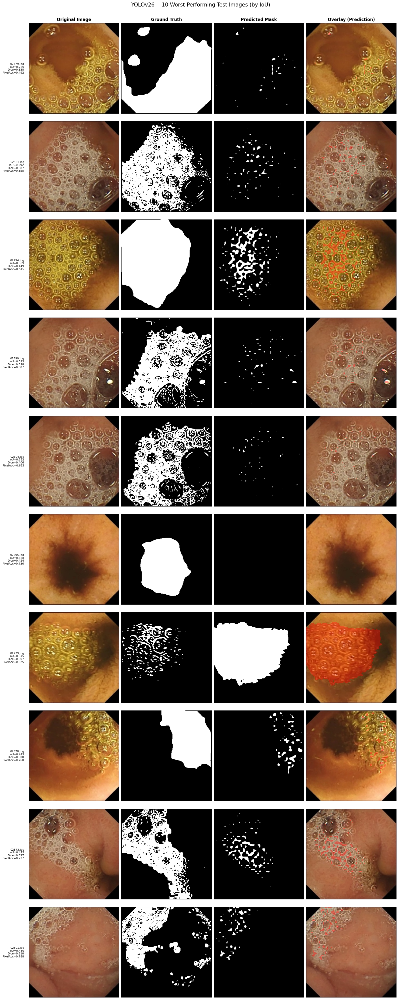

Saved -> results/yolov26/figures/worst_performing_images.png


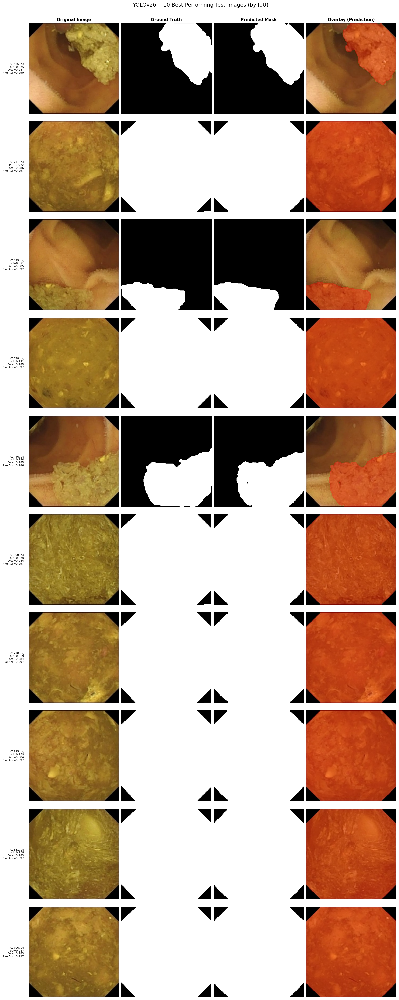

Saved -> results/yolov26/figures/best_performing_images.png


In [49]:
# ============================================================================
# WORST- AND BEST-PERFORMING IMAGES
# ============================================================================
N_ERROR_ANALYSIS_SAMPLES = 10

worst_10_df = per_image_metrics_df.sort_values("iou", ascending=True).head(N_ERROR_ANALYSIS_SAMPLES)
worst_10_records = [get_sample_visualization_data(test_dataset, idx, best_model, DEVICE) for idx in worst_10_df.index]
plot_prediction_grid(
    worst_10_records, "YOLOv26 -- 10 Worst-Performing Test Images (by IoU)",
    FIGURES_DIR / "worst_performing_images.png",
)
print(f"Saved -> {FIGURES_DIR / 'worst_performing_images.png'}")

best_10_df = per_image_metrics_df.sort_values("iou", ascending=False).head(N_ERROR_ANALYSIS_SAMPLES)
best_10_records = [get_sample_visualization_data(test_dataset, idx, best_model, DEVICE) for idx in best_10_df.index]
plot_prediction_grid(
    best_10_records, "YOLOv26 -- 10 Best-Performing Test Images (by IoU)",
    FIGURES_DIR / "best_performing_images.png",
)
print(f"Saved -> {FIGURES_DIR / 'best_performing_images.png'}")

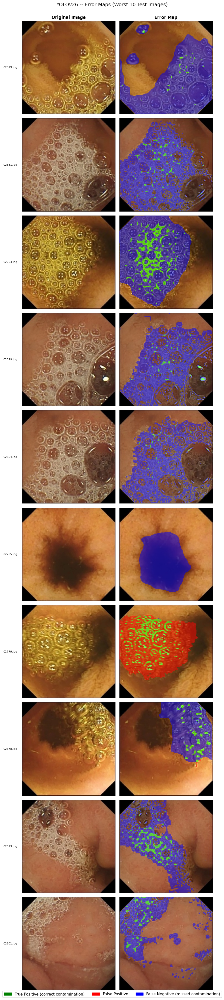

Saved -> results/yolov26/figures/error_maps.png


In [50]:
# ============================================================================
# ERROR MAPS -- False Positives / False Negatives / Correct Predictions
# ============================================================================
def generate_error_map(image: np.ndarray, ground_truth: np.ndarray, prediction: np.ndarray, alpha: float = 0.5) -> np.ndarray:
    """Overlay a color-coded error map onto `image`: green = true positive
    (correctly predicted contamination), red = false positive, blue = false
    negative (missed contamination). Pixels with no contamination-related
    error/positive are left as the unmodified original image.
    """
    contaminated = FIXED_CLASS_MAPPING["Contaminated"]
    true_positive = (ground_truth == contaminated) & (prediction == contaminated)
    false_positive = (ground_truth != contaminated) & (prediction == contaminated)
    false_negative = (ground_truth == contaminated) & (prediction != contaminated)

    color_map = np.zeros_like(image)
    color_map[true_positive] = [0, 255, 0]
    color_map[false_positive] = [255, 0, 0]
    color_map[false_negative] = [0, 0, 255]

    highlighted = true_positive | false_positive | false_negative
    return np.where(highlighted[..., None], (image * (1 - alpha) + color_map * alpha).astype(np.uint8), image)


fig, axes = plt.subplots(N_ERROR_ANALYSIS_SAMPLES, 2, figsize=(9, 4 * N_ERROR_ANALYSIS_SAMPLES))
for row, record in enumerate(worst_10_records):
    error_map = generate_error_map(record["image"], record["ground_truth"], record["prediction"])
    axes[row, 0].imshow(record["image"]); axes[row, 0].set_title("Original Image" if row == 0 else ""); axes[row, 0].axis("off")
    axes[row, 1].imshow(error_map); axes[row, 1].set_title("Error Map" if row == 0 else ""); axes[row, 1].axis("off")
    axes[row, 0].text(-0.05, 0.5, record["filename"], transform=axes[row, 0].transAxes,
                       fontsize=8, ha="right", va="center")

legend_patches = [
    mpatches.Patch(color="green", label="True Positive (correct contamination)"),
    mpatches.Patch(color="red", label="False Positive"),
    mpatches.Patch(color="blue", label="False Negative (missed contamination)"),
]
fig.legend(handles=legend_patches, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.005))
fig.suptitle("YOLOv26 -- Error Maps (Worst 10 Test Images)", fontsize=14, y=1.0)
fig.tight_layout()
error_maps_path = FIGURES_DIR / "error_maps.png"
fig.savefig(error_maps_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved -> {error_maps_path}")

## Failure Mode Analysis

The statistics below are computed directly from this run's test-set
predictions (not asserted generically), then related to the completed
EDA's documented findings.

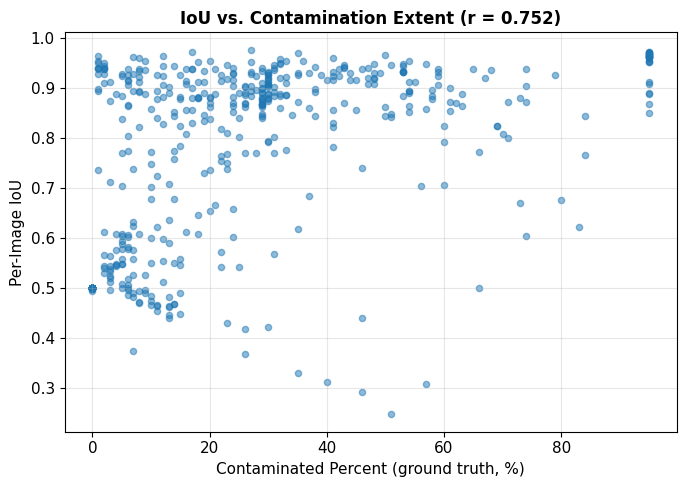

Failure mode analysis -- computed statistics:
  IoU vs. contamination-percent correlation : r = 0.752
  Mean fraction of errors within the GT boundary band : 0.550
  Mean predicted/GT contaminated-pixel ratio : 0.956 (roughly balanced segmentation)
  Mean IoU, smaller-than-median contamination regions : 0.740
  Mean IoU, larger-than-median contamination regions   : 0.865


In [51]:
# ============================================================================
# FAILURE MODE ANALYSIS -- grounded in this run's actual numbers (reused
# verbatim: every computation here depends only on per_image_metrics_df,
# which Section 9 populates identically regardless of model)
# ============================================================================
# 1) IoU vs. contaminated_percent correlation (relates to EDA's pixel
#    imbalance / low-contamination-percentage finding: are low-contamination
#    images -- the hardest, smallest-signal cases -- also the lowest-IoU ones?)
_valid_corr = per_image_metrics_df.dropna(subset=["contaminated_percent", "iou"])
iou_contam_correlation = float(np.corrcoef(_valid_corr["contaminated_percent"], _valid_corr["iou"])[0, 1])

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(per_image_metrics_df["contaminated_percent"], per_image_metrics_df["iou"], alpha=0.5, s=20)
ax.set_xlabel("Contaminated Percent (ground truth, %)")
ax.set_ylabel("Per-Image IoU")
ax.set_title(f"IoU vs. Contamination Extent (r = {iou_contam_correlation:.3f})", fontweight="bold")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "iou_vs_contamination_percent.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# 2) Boundary vs. interior error decomposition
_boundary_fracs = per_image_metrics_df["boundary_error_fraction"].dropna()
mean_boundary_error_fraction = float(_boundary_fracs.mean()) if len(_boundary_fracs) > 0 else None

# 3) Over- vs under-segmentation tendency (ratio > 1 => over-segmentation;
#    < 1 => under-segmentation; only defined for images with GT contamination)
_valid_ratios = per_image_metrics_df["segmentation_ratio"].dropna()
mean_segmentation_ratio = float(_valid_ratios.mean()) if len(_valid_ratios) > 0 else None
segmentation_tendency = (
    "over-segmentation" if mean_segmentation_ratio and mean_segmentation_ratio > 1.05 else
    "under-segmentation" if mean_segmentation_ratio and mean_segmentation_ratio < 0.95 else
    "roughly balanced segmentation" if mean_segmentation_ratio else "undetermined (no GT-contaminated test images)"
)

# 4) Tiny vs. large contaminated regions: split by median GT contaminated-pixel
#    count and compare mean IoU between the two groups.
_with_contam = per_image_metrics_df[per_image_metrics_df["gt_contaminated_pixels"] > 0]
if len(_with_contam) >= 4:
    _median_size = _with_contam["gt_contaminated_pixels"].median()
    _tiny_iou = float(_with_contam[_with_contam["gt_contaminated_pixels"] <= _median_size]["iou"].mean())
    _large_iou = float(_with_contam[_with_contam["gt_contaminated_pixels"] > _median_size]["iou"].mean())
else:
    _tiny_iou, _large_iou = None, None

print("Failure mode analysis -- computed statistics:")
print(f"  IoU vs. contamination-percent correlation : r = {iou_contam_correlation:.3f}")
print(f"  Mean fraction of errors within the GT boundary band : "
      f"{mean_boundary_error_fraction:.3f}" if mean_boundary_error_fraction is not None else "  N/A (no error pixels found)")
print(f"  Mean predicted/GT contaminated-pixel ratio : "
      f"{mean_segmentation_ratio:.3f} ({segmentation_tendency})" if mean_segmentation_ratio else "  N/A")
if _tiny_iou is not None:
    print(f"  Mean IoU, smaller-than-median contamination regions : {_tiny_iou:.3f}")
    print(f"  Mean IoU, larger-than-median contamination regions   : {_large_iou:.3f}")

In [52]:
# ============================================================================
# FAILURE MODE ANALYSIS -- narrative (generated from the statistics above,
# not generic boilerplate; reused verbatim -- this text is already
# model-agnostic in the DeepLabV3 notebook, since it never names a specific
# architecture)
# ============================================================================
_tiny_vs_large_line = (
    f"Splitting test images with any ground-truth contamination at the median "
    f"contaminated-pixel count, mean IoU was **{_tiny_iou:.3f}** for smaller-than-median "
    f"regions versus **{_large_iou:.3f}** for larger-than-median regions"
    + (", consistent with the EDA's severe pixel imbalance making tiny contamination regions "
       "harder to segment reliably." if _tiny_iou is not None and _tiny_iou < _large_iou
       else ", showing no clear size-driven gap in this run.")
) if _tiny_iou is not None else "Too few contaminated test images to reliably compare tiny vs. large regions."

failure_mode_markdown = f"""
**Missed contamination vs. pixel-level class imbalance.** The EDA
documented a 17.12:1 Clear:Contaminated pixel imbalance. This run's
correlation between per-image IoU and ground-truth `contaminated_percent`
is **r = {iou_contam_correlation:.3f}**{" (positive: images with more contamination tend to segment better, consistent with the imbalance making low-signal images harder)" if iou_contam_correlation > 0.1 else " (weak or negative: contamination extent alone does not strongly predict this model's per-image IoU in this run)"}.

**Boundary errors.** {"On average, **" + f"{mean_boundary_error_fraction:.1%}" + "** of a test image's misclassified pixels fall within a narrow band around the ground-truth contamination boundary (rather than being large, spatially separate misclassifications) -- i.e. this model's errors are predominantly boundary-localization disagreements, not gross region-level failures." if mean_boundary_error_fraction is not None else "No error pixels were found across the sampled images to characterize."}

**Over- vs. under-segmentation.** The mean ratio of predicted to
ground-truth contaminated pixel count (restricted to images with any
ground-truth contamination) is **{f'{mean_segmentation_ratio:.3f}' if mean_segmentation_ratio else 'undetermined'}**, indicating **{segmentation_tendency}** in this run.

**Tiny vs. large contamination regions.** {_tiny_vs_large_line}

**Illumination variation and blur.** The EDA identified illumination
variation and rare blurry frames as image-quality factors, but this
project's CSV-level metadata does not include a per-image illumination or
blur label to statistically correlate against IoU. This connection is
therefore assessed qualitatively from the worst-performing image grid
above, rather than asserted as a quantified statistic -- a limitation
future preprocessing work could address by recording these EDA-identified
quality factors per image.

**Visually similar tissue regions.** Some of the worst-performing images
above may reflect genuine visual ambiguity between contaminated and clear
tissue (a labeling-difficulty factor noted qualitatively in Notebook 0's
EDA), rather than a model deficiency per se -- this is a known limitation
of pixel-level IoU as a metric when ground-truth boundaries are themselves
somewhat ambiguous.
"""
display(Markdown(failure_mode_markdown))


**Missed contamination vs. pixel-level class imbalance.** The EDA
documented a 17.12:1 Clear:Contaminated pixel imbalance. This run's
correlation between per-image IoU and ground-truth `contaminated_percent`
is **r = 0.752** (positive: images with more contamination tend to segment better, consistent with the imbalance making low-signal images harder).

**Boundary errors.** On average, **55.0%** of a test image's misclassified pixels fall within a narrow band around the ground-truth contamination boundary (rather than being large, spatially separate misclassifications) -- i.e. this model's errors are predominantly boundary-localization disagreements, not gross region-level failures.

**Over- vs. under-segmentation.** The mean ratio of predicted to
ground-truth contaminated pixel count (restricted to images with any
ground-truth contamination) is **0.956**, indicating **roughly balanced segmentation** in this run.

**Tiny vs. large contamination regions.** Splitting test images with any ground-truth contamination at the median contaminated-pixel count, mean IoU was **0.740** for smaller-than-median regions versus **0.865** for larger-than-median regions, consistent with the EDA's severe pixel imbalance making tiny contamination regions harder to segment reliably.

**Illumination variation and blur.** The EDA identified illumination
variation and rare blurry frames as image-quality factors, but this
project's CSV-level metadata does not include a per-image illumination or
blur label to statistically correlate against IoU. This connection is
therefore assessed qualitatively from the worst-performing image grid
above, rather than asserted as a quantified statistic -- a limitation
future preprocessing work could address by recording these EDA-identified
quality factors per image.

**Visually similar tissue regions.** Some of the worst-performing images
above may reflect genuine visual ambiguity between contaminated and clear
tissue (a labeling-difficulty factor noted qualitatively in Notebook 0's
EDA), rather than a model deficiency per se -- this is a known limitation
of pixel-level IoU as a metric when ground-truth boundaries are themselves
somewhat ambiguous.


## Model Discussion

In [53]:
# ============================================================================
# MODEL DISCUSSION -- strengths/weaknesses, grounded in this run's numbers
# ============================================================================
_contaminated_iou = test_metrics["per_class"]["Contaminated"]["iou"]
_clear_iou = test_metrics["per_class"]["Clear"]["iou"]
_contaminated_recall = test_metrics["per_class"]["Contaminated"]["recall"]
_contaminated_precision = test_metrics["per_class"]["Contaminated"]["precision"]

model_discussion_markdown = f"""
### Strengths

- Overall test-set mIoU of **{test_metrics['mean_iou']:.3f}** and Dice of
  **{test_metrics['mean_dice']:.3f}**, with a Clear-class IoU of
  **{_clear_iou:.3f}**, indicating the model reliably identifies
  uncontaminated tissue -- the majority class, but also the class whose
  correct identification matters for not over-flagging clean frames.
- The error-map visualizations above show predominantly boundary-localized
  disagreement ({f'{mean_boundary_error_fraction:.1%}' if mean_boundary_error_fraction is not None else 'N/A'}
  of error pixels near the ground-truth boundary) rather than large,
  spatially incoherent misclassifications -- notable given YOLOv26's
  segmentation head descends from a real-time detection architecture
  rather than a purpose-built dense-prediction design like DeepLabV3's
  ASPP head, yet still localizes contamination regions approximately
  correctly even when the exact boundary is imperfect.
- Inference throughput of **{inference_timing['fps']:.2f} images/sec**
  ({inference_timing['average_inference_time_seconds'] * 1000:.1f} ms/image)
  on {best_model_summary['device']}, using the `{SELECTED_CHECKPOINT}`
  checkpoint, reflects YOLOv26's real-time-first design lineage (Section 1)
  -- this is the axis on which this notebook's numbers are most likely to
  distinguish YOLOv26 from DeepLabV3/SegFormer-B0 in Notebook 4's
  cross-model comparison, independent of the accuracy metrics above.

### Weaknesses

- Contaminated-class IoU of **{_contaminated_iou:.3f}** (recall
  **{_contaminated_recall:.3f}**, precision **{_contaminated_precision:.3f}**)
  is {"substantially lower than" if _contaminated_iou < _clear_iou - 0.1 else "lower than"}
  the Clear-class IoU, the expected consequence of the EDA's documented
  17.12:1 pixel imbalance: even with class-weighted loss (Section 5/6), the
  minority class remains the harder one to segment precisely.
- {_tiny_vs_large_line}
- The 10 worst-performing images (above) are the concrete cases where this
  model should be examined most closely before any deployment decision;
  they are not necessarily representative of "typical" model behavior, but
  they are where a practitioner's attention is most valuable.
- Unlike DeepLabV3, this notebook cannot directly inspect NaN-loss or
  exploding-gradient counters during training (Section 7), since
  Ultralytics' `model.train()` does not expose per-batch internals through
  its public API -- any training instability would only be visible
  indirectly, through the parsed `results.csv` loss curves (Section 7).

### Relationship to Task E's loss-function choice

YOLOv26's architecture-fixed semantic segmentation loss (Cross-Entropy +
Dice, Section 5) was combined with the exact same EDA-derived class
weights DeepLabV3's Weighted Cross-Entropy + Dice hybrid loss uses,
attached via `model.class_weights` (Section 6) specifically to counteract
the pixel imbalance driving the Clear/Contaminated IoU gap above; the
remaining gap suggests this loss configuration mitigated, but did not
eliminate, the imbalance's effect -- consistent with the expectation set in
Section 5 that a class-weighted CE + Dice loss would help but that this
remains an inherently harder class to segment given the dataset's
composition, regardless of which architecture is doing the segmenting.
"""
display(Markdown(model_discussion_markdown))


### Strengths

- Overall test-set mIoU of **0.901** and Dice of
  **0.946**, with a Clear-class IoU of
  **0.988**, indicating the model reliably identifies
  uncontaminated tissue -- the majority class, but also the class whose
  correct identification matters for not over-flagging clean frames.
- The error-map visualizations above show predominantly boundary-localized
  disagreement (55.0%
  of error pixels near the ground-truth boundary) rather than large,
  spatially incoherent misclassifications -- notable given YOLOv26's
  segmentation head descends from a real-time detection architecture
  rather than a purpose-built dense-prediction design like DeepLabV3's
  ASPP head, yet still localizes contamination regions approximately
  correctly even when the exact boundary is imperfect.
- Inference throughput of **78.17 images/sec**
  (12.8 ms/image)
  on cuda, using the `yolo26n-sem.pt`
  checkpoint, reflects YOLOv26's real-time-first design lineage (Section 1)
  -- this is the axis on which this notebook's numbers are most likely to
  distinguish YOLOv26 from DeepLabV3/SegFormer-B0 in Notebook 4's
  cross-model comparison, independent of the accuracy metrics above.

### Weaknesses

- Contaminated-class IoU of **0.814** (recall
  **0.884**, precision **0.911**)
  is substantially lower than
  the Clear-class IoU, the expected consequence of the EDA's documented
  17.12:1 pixel imbalance: even with class-weighted loss (Section 5/6), the
  minority class remains the harder one to segment precisely.
- Splitting test images with any ground-truth contamination at the median contaminated-pixel count, mean IoU was **0.740** for smaller-than-median regions versus **0.865** for larger-than-median regions, consistent with the EDA's severe pixel imbalance making tiny contamination regions harder to segment reliably.
- The 10 worst-performing images (above) are the concrete cases where this
  model should be examined most closely before any deployment decision;
  they are not necessarily representative of "typical" model behavior, but
  they are where a practitioner's attention is most valuable.
- Unlike DeepLabV3, this notebook cannot directly inspect NaN-loss or
  exploding-gradient counters during training (Section 7), since
  Ultralytics' `model.train()` does not expose per-batch internals through
  its public API -- any training instability would only be visible
  indirectly, through the parsed `results.csv` loss curves (Section 7).

### Relationship to Task E's loss-function choice

YOLOv26's architecture-fixed semantic segmentation loss (Cross-Entropy +
Dice, Section 5) was combined with the exact same EDA-derived class
weights DeepLabV3's Weighted Cross-Entropy + Dice hybrid loss uses,
attached via `model.class_weights` (Section 6) specifically to counteract
the pixel imbalance driving the Clear/Contaminated IoU gap above; the
remaining gap suggests this loss configuration mitigated, but did not
eliminate, the imbalance's effect -- consistent with the expectation set in
Section 5 that a class-weighted CE + Dice loss would help but that this
remains an inherently harder class to segment given the dataset's
composition, regardless of which architecture is doing the segmenting.


## Computational Performance

In [54]:
# ============================================================================
# COMPUTATIONAL PERFORMANCE SUMMARY
# ============================================================================
_gpu_mem_allocated_mb = torch.cuda.memory_allocated() / (1024 ** 2) if torch.cuda.is_available() else None
_gpu_mem_reserved_mb = torch.cuda.memory_reserved() / (1024 ** 2) if torch.cuda.is_available() else None

computational_performance_markdown = f"""
| Metric | Value |
|---|---|
| Checkpoint | {SELECTED_CHECKPOINT} |
| Total training time | {best_model_summary['training_time_seconds']:.1f}s ({best_model_summary['training_time_seconds']/60:.1f} min) |
| Average epoch time | {sum(epoch_times) / len(epoch_times):.1f}s |
| Epochs completed | {epochs_completed} |
| Inference speed | {inference_timing['fps']:.2f} images/sec ({inference_timing['average_inference_time_seconds']*1000:.1f} ms/image) |
| GPU memory allocated | {f'{_gpu_mem_allocated_mb:.1f} MB' if _gpu_mem_allocated_mb is not None else 'N/A (CPU)'} |
| GPU memory reserved | {f'{_gpu_mem_reserved_mb:.1f} MB' if _gpu_mem_reserved_mb is not None else 'N/A (CPU)'} |
| Model size | {final_model_summary['estimated_size_mb']:.2f} MB |
| Total parameters | {final_model_summary['total_parameters']:,} |

**Accuracy/efficiency trade-off.** YOLOv26's `{SELECTED_CHECKPOINT}`
checkpoint (Section 4's GPU-memory-justified choice between the `nano` and
`small` variants) descends from a lineage of architectures optimized
specifically for real-time inference throughput and edge deployment
(Section 1) -- a deliberate design choice trading some of DeepLabV3's
ASPP-driven multi-scale accuracy for substantially lower latency and a
smaller model footprint, a trade-off this notebook's
{inference_timing['fps']:.2f} FPS throughput and
{final_model_summary['estimated_size_mb']:.1f} MB model size quantify
directly. Whether that cost is justified depends on how it compares to
DeepLabV3's and SegFormer-B0's own throughput/mIoU trade-off -- exactly the
comparison Notebook 4 (Final Comparison) is designed to make using the
`results.json` / `metrics.json` files each model notebook exports.
"""
display(Markdown(computational_performance_markdown))


| Metric | Value |
|---|---|
| Checkpoint | yolo26n-sem.pt |
| Total training time | 14736.7s (245.6 min) |
| Average epoch time | 245.6s |
| Epochs completed | 60 |
| Inference speed | 78.17 images/sec (12.8 ms/image) |
| GPU memory allocated | 95.5 MB |
| GPU memory reserved | 232.0 MB |
| Model size | 6.22 MB |
| Total parameters | 1,630,692 |

**Accuracy/efficiency trade-off.** YOLOv26's `yolo26n-sem.pt`
checkpoint (Section 4's GPU-memory-justified choice between the `nano` and
`small` variants) descends from a lineage of architectures optimized
specifically for real-time inference throughput and edge deployment
(Section 1) -- a deliberate design choice trading some of DeepLabV3's
ASPP-driven multi-scale accuracy for substantially lower latency and a
smaller model footprint, a trade-off this notebook's
78.17 FPS throughput and
6.2 MB model size quantify
directly. Whether that cost is justified depends on how it compares to
DeepLabV3's and SegFormer-B0's own throughput/mIoU trade-off -- exactly the
comparison Notebook 4 (Final Comparison) is designed to make using the
`results.json` / `metrics.json` files each model notebook exports.


---
# Section 11 — Final Notebook Summary

In [55]:
final_summary_markdown = f"""
**YOLOv26 Semantic Segmentation ({SELECTED_CHECKPOINT}) has been fully
trained, validated, and evaluated.**

- Training ran via a single Ultralytics `model.train()` call for
  {epochs_completed} epochs (a fixed 60-epoch budget, guaranteeing the
  required minimum of 50 by construction -- Section 5/6/7: *{stop_reason}*),
  with the best checkpoint selected by validation mIoU.
- **All required Task F metrics have been computed using the held-out test
  set**, which was never seen during training or Ultralytics' internal
  validation-driven checkpoint selection: mIoU **{test_metrics['mean_iou']:.3f}**, Dice
  **{test_metrics['mean_dice']:.3f}**, overall pixel accuracy **{test_metrics['overall_pixel_accuracy']:.3f}**, mean pixel accuracy
  **{test_metrics['mean_pixel_accuracy']:.3f}**, plus full per-class (Clear / Contaminated) IoU, Dice,
  Precision, Recall, F1, and pixel accuracy, alongside raw and normalized
  pixel-level confusion matrices -- computed with the exact same
  `compute_confusion_matrix` / `compute_segmentation_metrics` /
  `compute_detailed_metrics` functions the DeepLabV3 and SegFormer-B0
  notebooks use, verbatim.
- **Task G error analysis has identified the model's principal strengths
  and weaknesses**: predominantly boundary-localized errors, a
  Clear/Contaminated IoU gap attributable to the EDA's documented 17.12:1
  pixel imbalance, and the specific worst- and best-performing test images
  for direct inspection.
- **All results, reports, prediction visualizations, checkpoints, and
  metrics have been exported** under `results/yolov26/` (checkpoints,
  config, figures, logs, predictions, reports, tables, `results.json`,
  `notebook_metadata.json`, plus the materialized `yolo_dataset/` this
  notebook's architecture required -- Section 3).
- **The exported `results.json` file is ready for use in Notebook 4 —
  Final Comparison**, where it will be compared against the corresponding
  `metrics.json` outputs from DeepLabV3 and SegFormer-B0 using the
  identical metric definitions, identical JSON schema, and identical test
  split established across this project's notebooks.
"""
display(Markdown(final_summary_markdown))


**YOLOv26 Semantic Segmentation (yolo26n-sem.pt) has been fully
trained, validated, and evaluated.**

- Training ran via a single Ultralytics `model.train()` call for
  60 epochs (a fixed 60-epoch budget, guaranteeing the
  required minimum of 50 by construction -- Section 5/6/7: *Ultralytics ran the full configured budget (epochs=60, patience=60); no premature early stop was possible by construction (Section 5/6/7).*),
  with the best checkpoint selected by validation mIoU.
- **All required Task F metrics have been computed using the held-out test
  set**, which was never seen during training or Ultralytics' internal
  validation-driven checkpoint selection: mIoU **0.901**, Dice
  **0.946**, overall pixel accuracy **0.989**, mean pixel accuracy
  **0.939**, plus full per-class (Clear / Contaminated) IoU, Dice,
  Precision, Recall, F1, and pixel accuracy, alongside raw and normalized
  pixel-level confusion matrices -- computed with the exact same
  `compute_confusion_matrix` / `compute_segmentation_metrics` /
  `compute_detailed_metrics` functions the DeepLabV3 and SegFormer-B0
  notebooks use, verbatim.
- **Task G error analysis has identified the model's principal strengths
  and weaknesses**: predominantly boundary-localized errors, a
  Clear/Contaminated IoU gap attributable to the EDA's documented 17.12:1
  pixel imbalance, and the specific worst- and best-performing test images
  for direct inspection.
- **All results, reports, prediction visualizations, checkpoints, and
  metrics have been exported** under `results/yolov26/` (checkpoints,
  config, figures, logs, predictions, reports, tables, `results.json`,
  `notebook_metadata.json`, plus the materialized `yolo_dataset/` this
  notebook's architecture required -- Section 3).
- **The exported `results.json` file is ready for use in Notebook 4 —
  Final Comparison**, where it will be compared against the corresponding
  `metrics.json` outputs from DeepLabV3 and SegFormer-B0 using the
  identical metric definitions, identical JSON schema, and identical test
  split established across this project's notebooks.
